In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import math

Veri temizleme düzeltme boşluk doldurma işlemleri


In [3]:
#!pip install missingno


In [4]:
data=pd.read_csv('1-merged_dataset.csv',sep=',')
df=data.copy()

In [5]:
cat=[col for col  in df.columns if df[col].dtype=='O']
cat
for col in cat:
    print(col," ",len(df[col].unique()))

OASISID   1378
meds_1   1299
meds_2   1450
meds_3   1452
meds_4   1457
dx1   55
dx2   73
dx3   51
dx4   33
dx5   23


In [6]:
for col in df.columns:
    df[col]=df[col].replace(9,np.nan)

In [7]:
df.columns

Index(['OASISID', 'age at visit', 'ANIMALS', 'asscmem', 'srtfree', 'srttotal',
       'tma', 'tmb', 'INDEPEND', 'RESIDENC', 'MARISTAT', 'INSEX', 'INRELTO',
       'INLIVWTH', 'INRELY', 'anymeds', 'meds_1', 'meds_2', 'meds_3', 'meds_4',
       'WEIGHT', 'BPSYS', 'BPDIAS', 'MMSE', 'memory', 'orient', 'judgment',
       'commun', 'homehobb', 'perscare', 'CDRSUM', 'CDRTOT', 'dx1_code', 'dx1',
       'dx2', 'dx3', 'dx4', 'dx5', 'NPIQINF', 'DEL', 'HALL', 'AGIT', 'DEPD',
       'ANX', 'ELAT', 'APA', 'DISN', 'IRR', 'MOT', 'NITE', 'APP', 'SATIS',
       'DROPACT', 'EMPTY', 'BORED', 'SPIRITS', 'AFRAID', 'HAPPY', 'HELPLESS',
       'STAYHOME', 'MEMPROB', 'WONDRFUL', 'WRTHLESS', 'ENERGY', 'HOPELESS',
       'BETTER', 'GDS', 'BILLS', 'TAXES', 'SHOPPING', 'GAMES', 'STOVE',
       'MEALPREP', 'EVENTS', 'PAYATTN', 'REMDATES', 'TRAVEL', 'DECSUB',
       'DECIN', 'NORMCOG', 'PSP', 'CORT', 'HUNT', 'PRION', 'MEDS', 'DYSILL',
       'DEP', 'OTHPSY', 'DOWNS', 'PARK', 'HYCEPH', 'BRNINJ', 'NEOP', 'COGOTH',
  

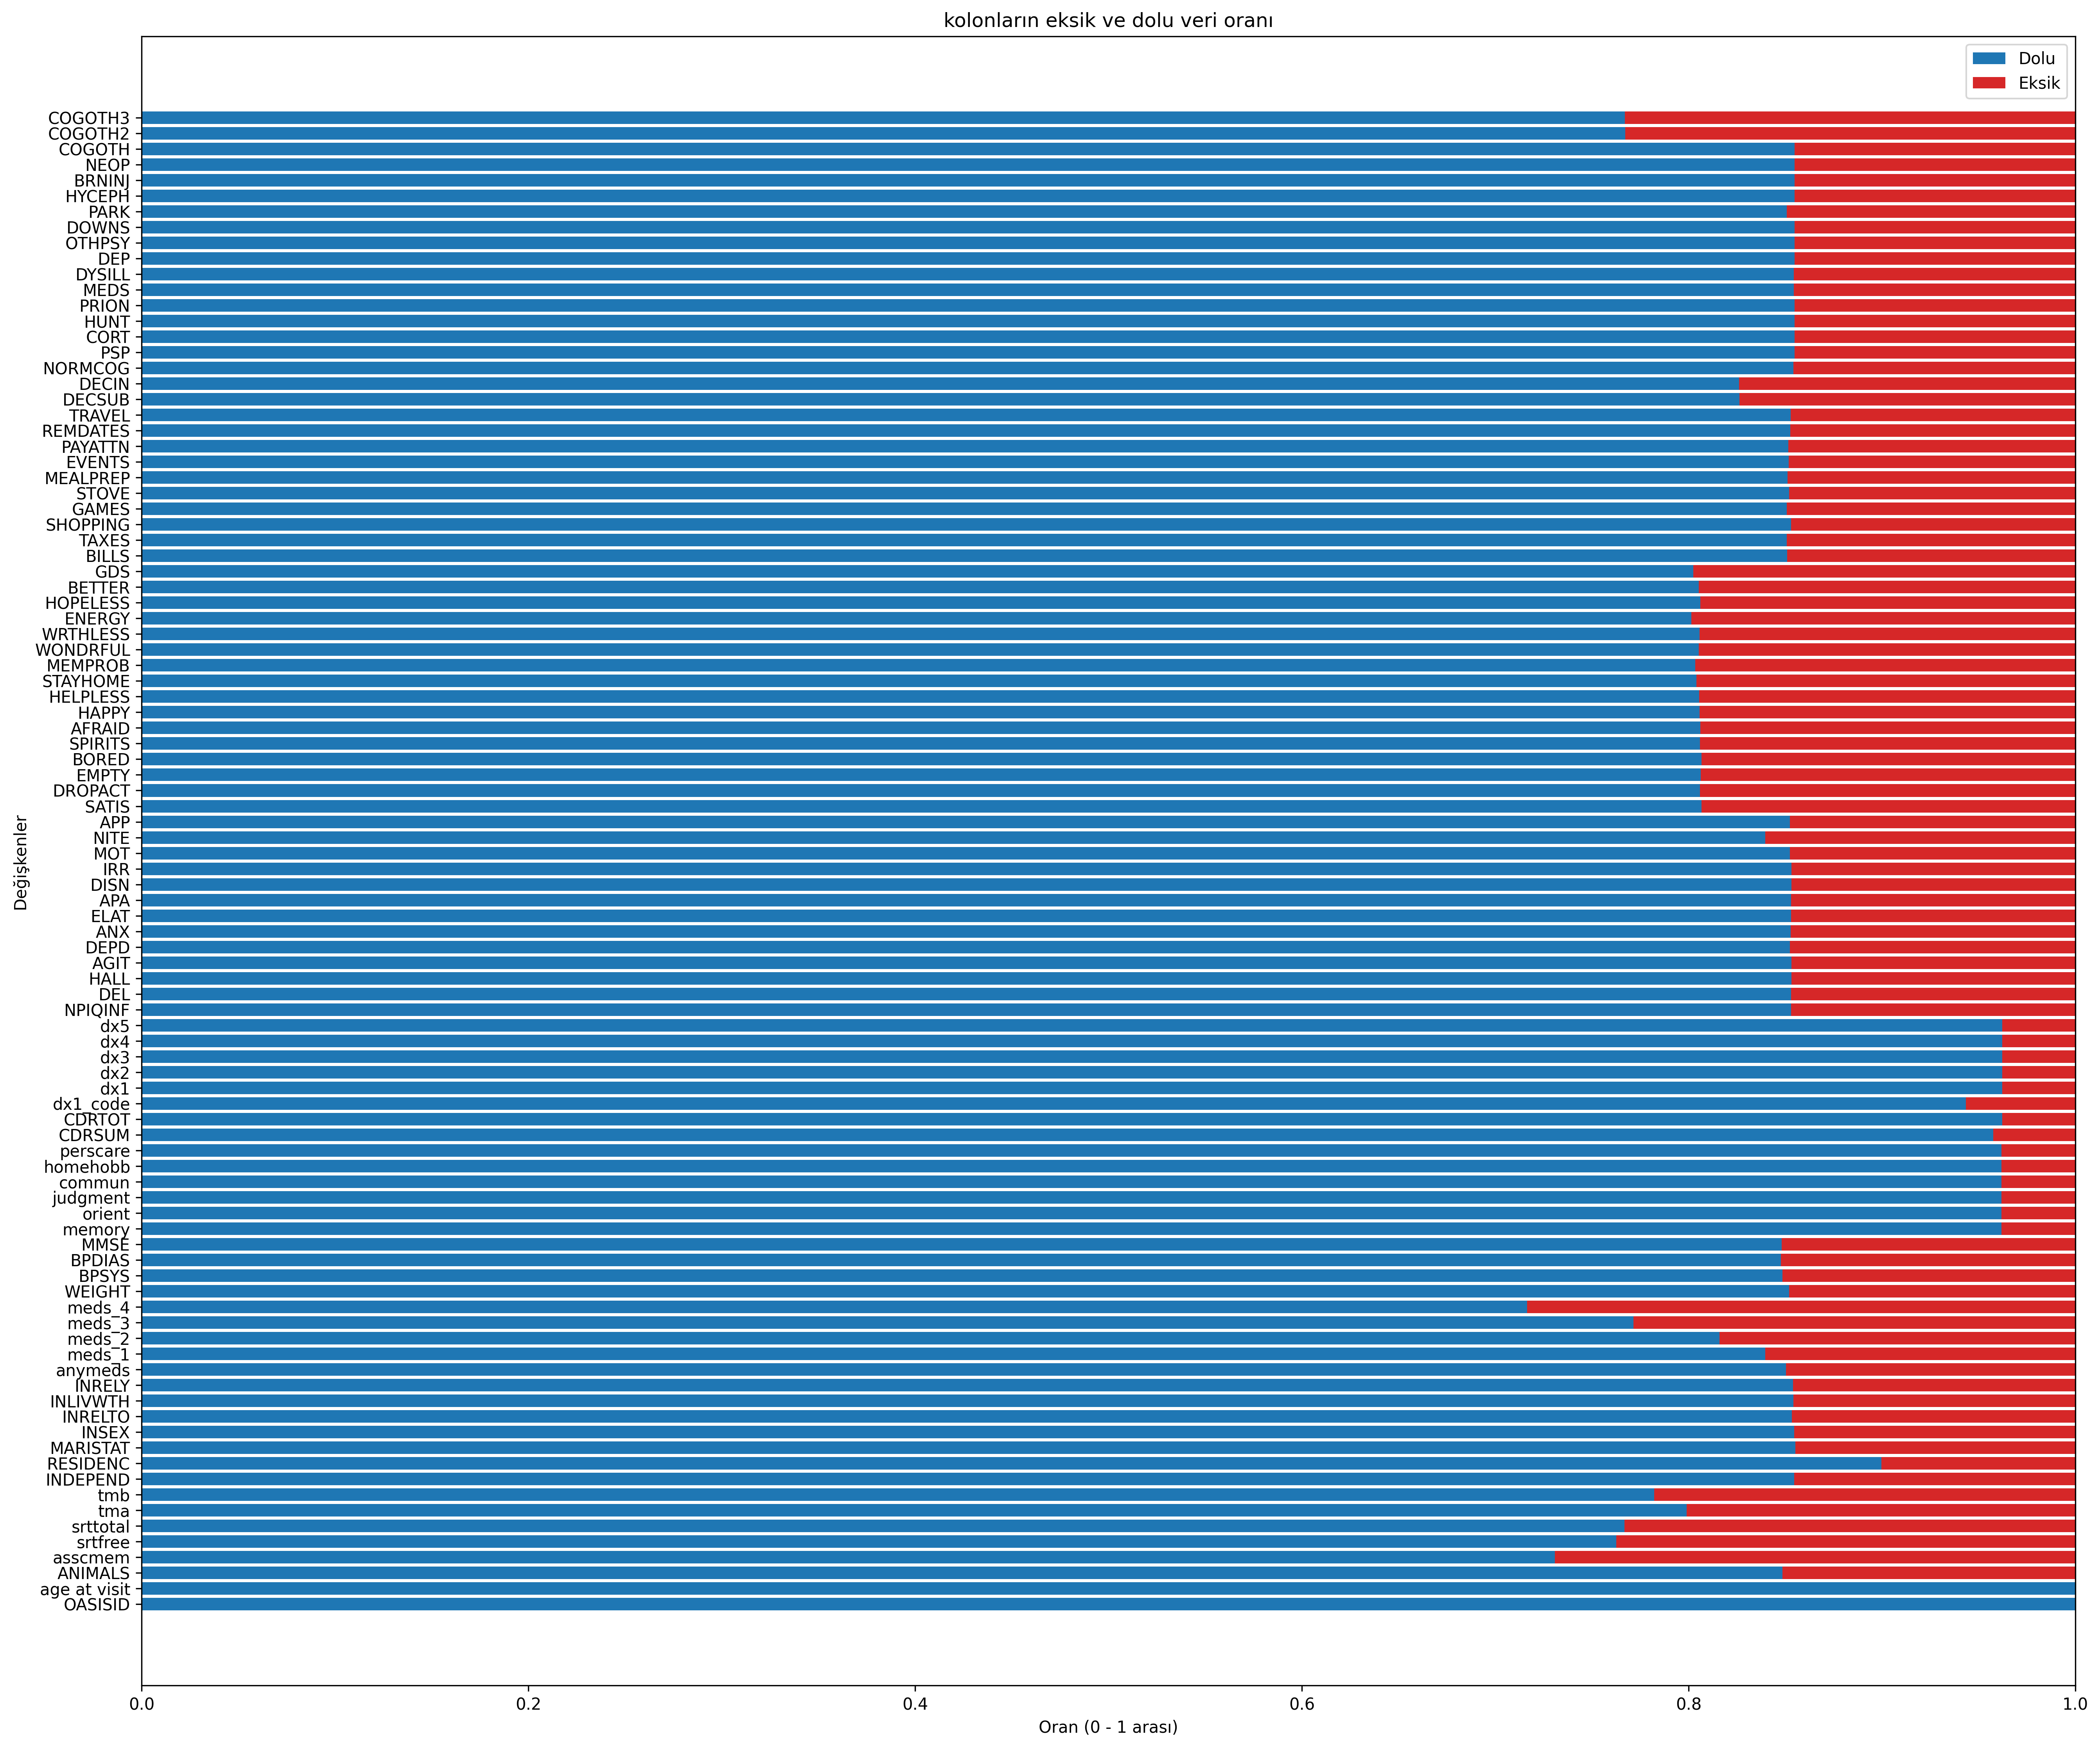

In [8]:
#EKSİK VE DOLU VERİLERİN ORANININ GÖRSELLEŞTİRİLMESİ

import pandas as pd
import matplotlib.pyplot as plt
def visualize_all():
    # Eksik oranlarını hesapla
    missing_counts = df.isnull().sum() #HER BİR KOLONUN EKSİK VERİ DEĞERİNİ ALMA
    total = len(df) #TOPLAM DATA UZUNLUĞU
    missing_ratio = missing_counts / total #HER BİR KOLON İÇİN YÜZDE OLARAK EKSİKLİK ORANI


    fig, ax = plt.subplots(figsize=(18,15), dpi=300)


    ax.barh(df.columns, 1 - missing_ratio, color='#1f77b4', label='Dolu') #DOLU KISIMNLARI GÖRSELLEŞTİRME

    # Eksik kısım (örneğin kırmızı)
    ax.barh(df.columns, missing_ratio, left=1 - missing_ratio, color='#d62728', label='Eksik') #EKSİK KISIMLAR LEFT PARAMETRESİ KULLANARAK OKUNABİLİRLİĞİ ARTIRDIK.

    ax.set_xlabel("Oran (0 - 1 arası)")
    ax.set_ylabel("Değişkenler")
    ax.set_title("kolonların eksik ve dolu veri oranı")
    ax.legend()
    plt.tight_layout()
    plt.show()

visualize_all()


In [9]:
float_cols=[col for col in df.columns if df[col].dtype=='float64'] #sayısal kolonların alınması

In [10]:
ilk_dort=float_cols[:4:]

In [11]:
df=data.copy()

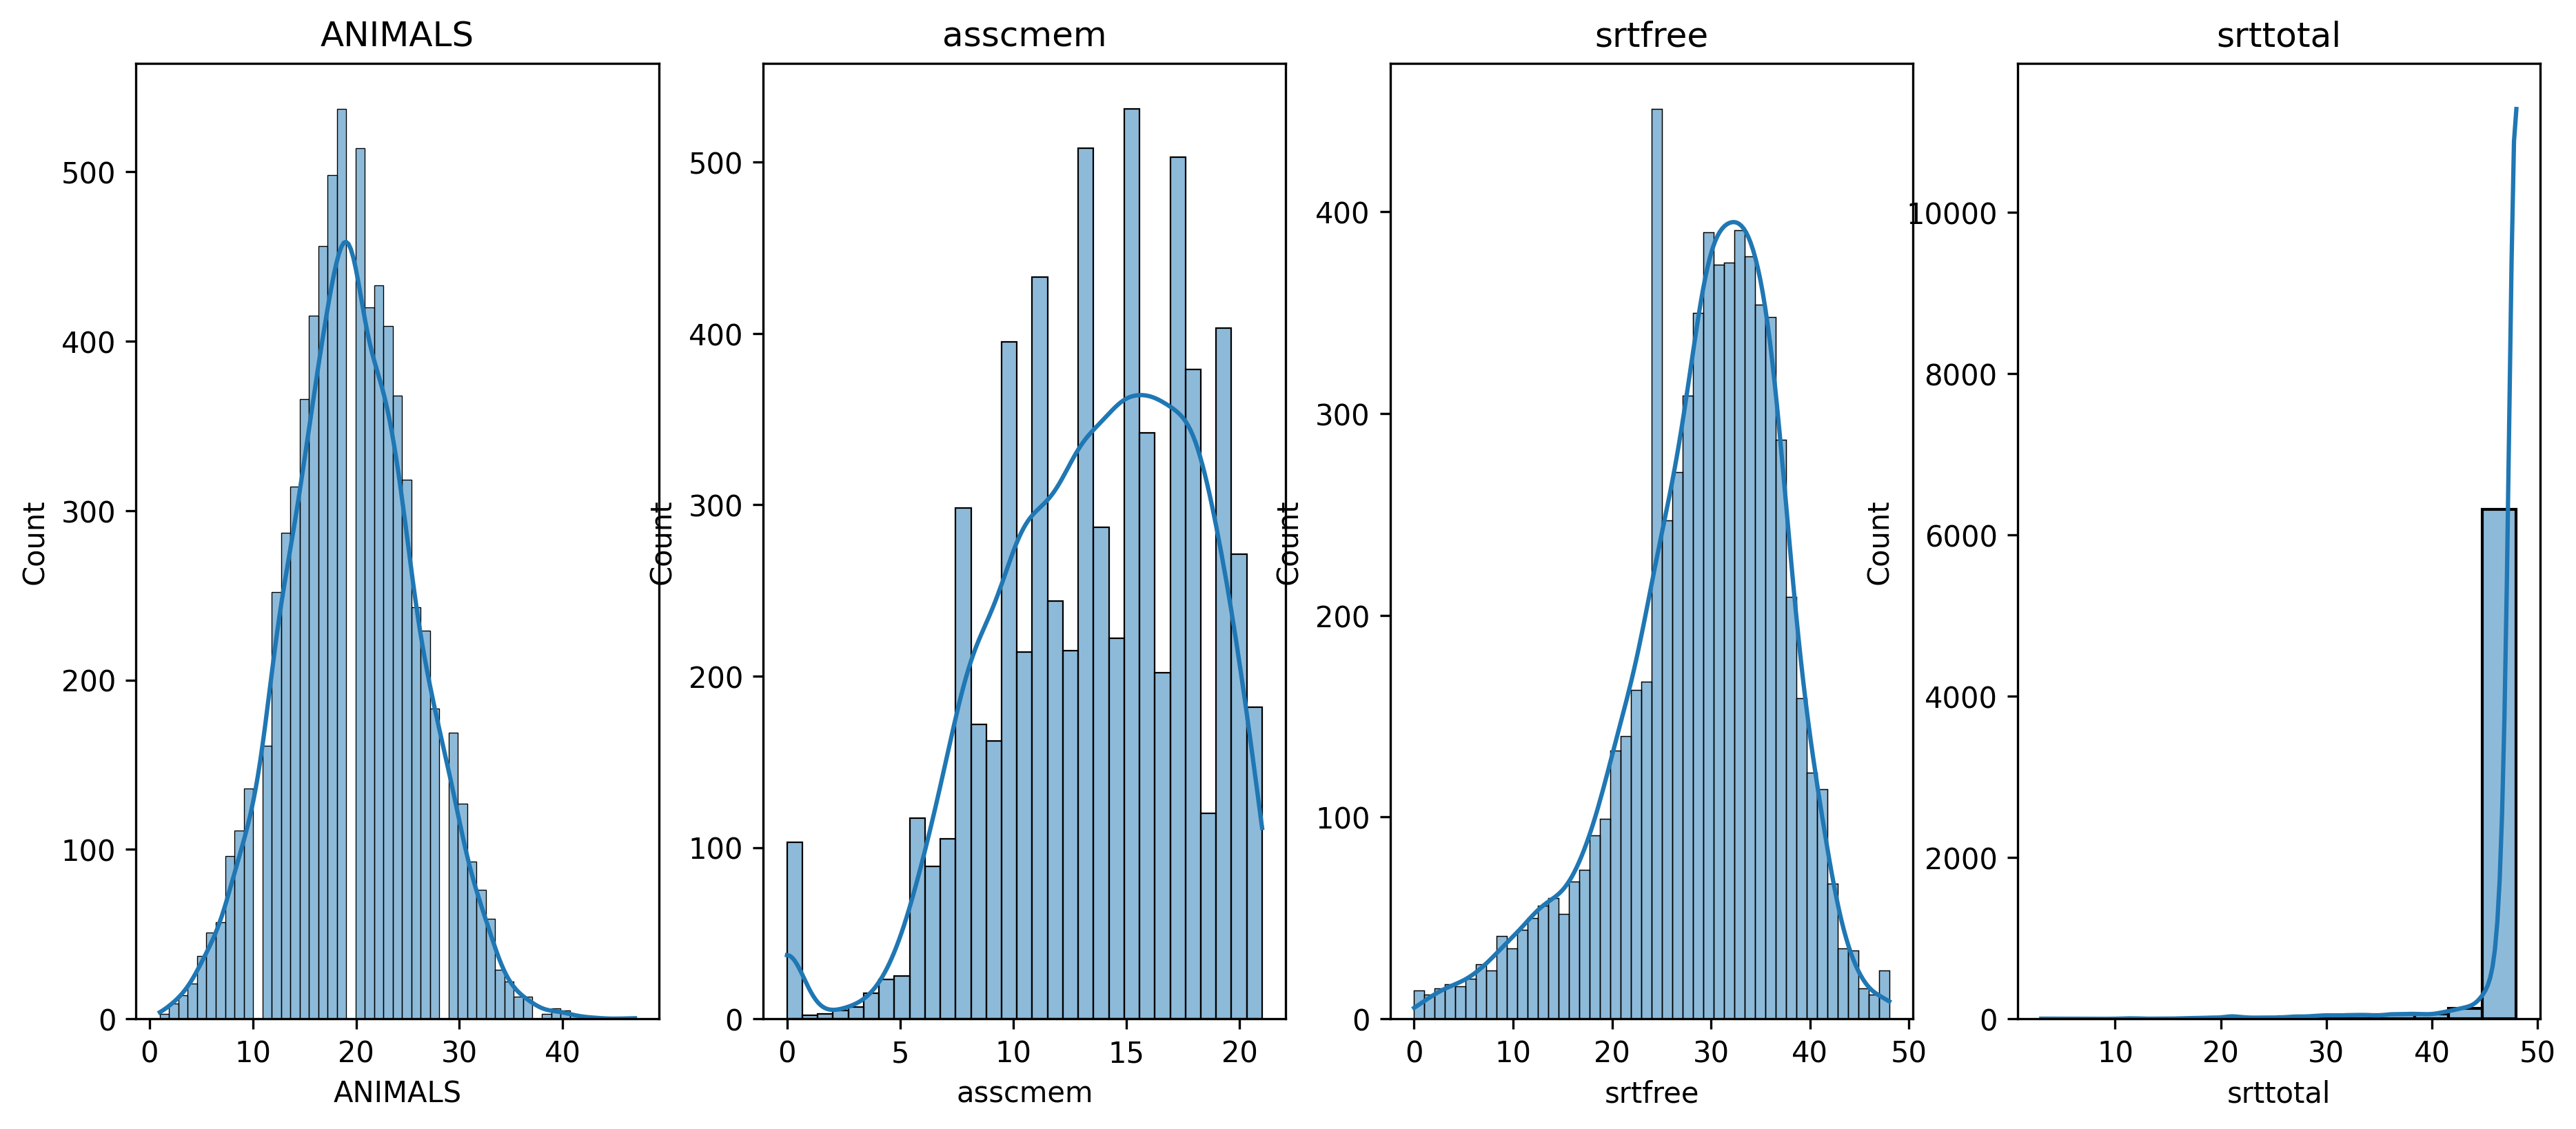

<Figure size 640x480 with 0 Axes>

In [12]:
fig,axes=plt.subplots(1,4,figsize=(15,6),dpi=300)

for i,col in enumerate(ilk_dort):
    sns.histplot(data=df[col],kde=True,ax=axes[i])
    axes[i].set_title(col)

plt.show()
plt.tight_layout()

In [13]:
#GRAFİKTEKİ DAĞILIMA GÖRE EKSİK VERİ DOLDURMA İŞLEMİ SEÇİLDİ

In [14]:
from sklearn.impute import SimpleImputer,KNNImputer


In [15]:
imputer=KNNImputer(n_neighbors=3)

In [16]:
df['ANIMALS']=imputer.fit_transform(df[['ANIMALS']])
df['ANIMALS'] = df['ANIMALS'].round().astype(int)

In [17]:
imputer=SimpleImputer(strategy='median')
df[['asscmem','srtfree']]=imputer.fit_transform(df[['asscmem','srtfree']])

In [18]:
df['srttotal']=imputer.fit_transform(df[['srttotal']])

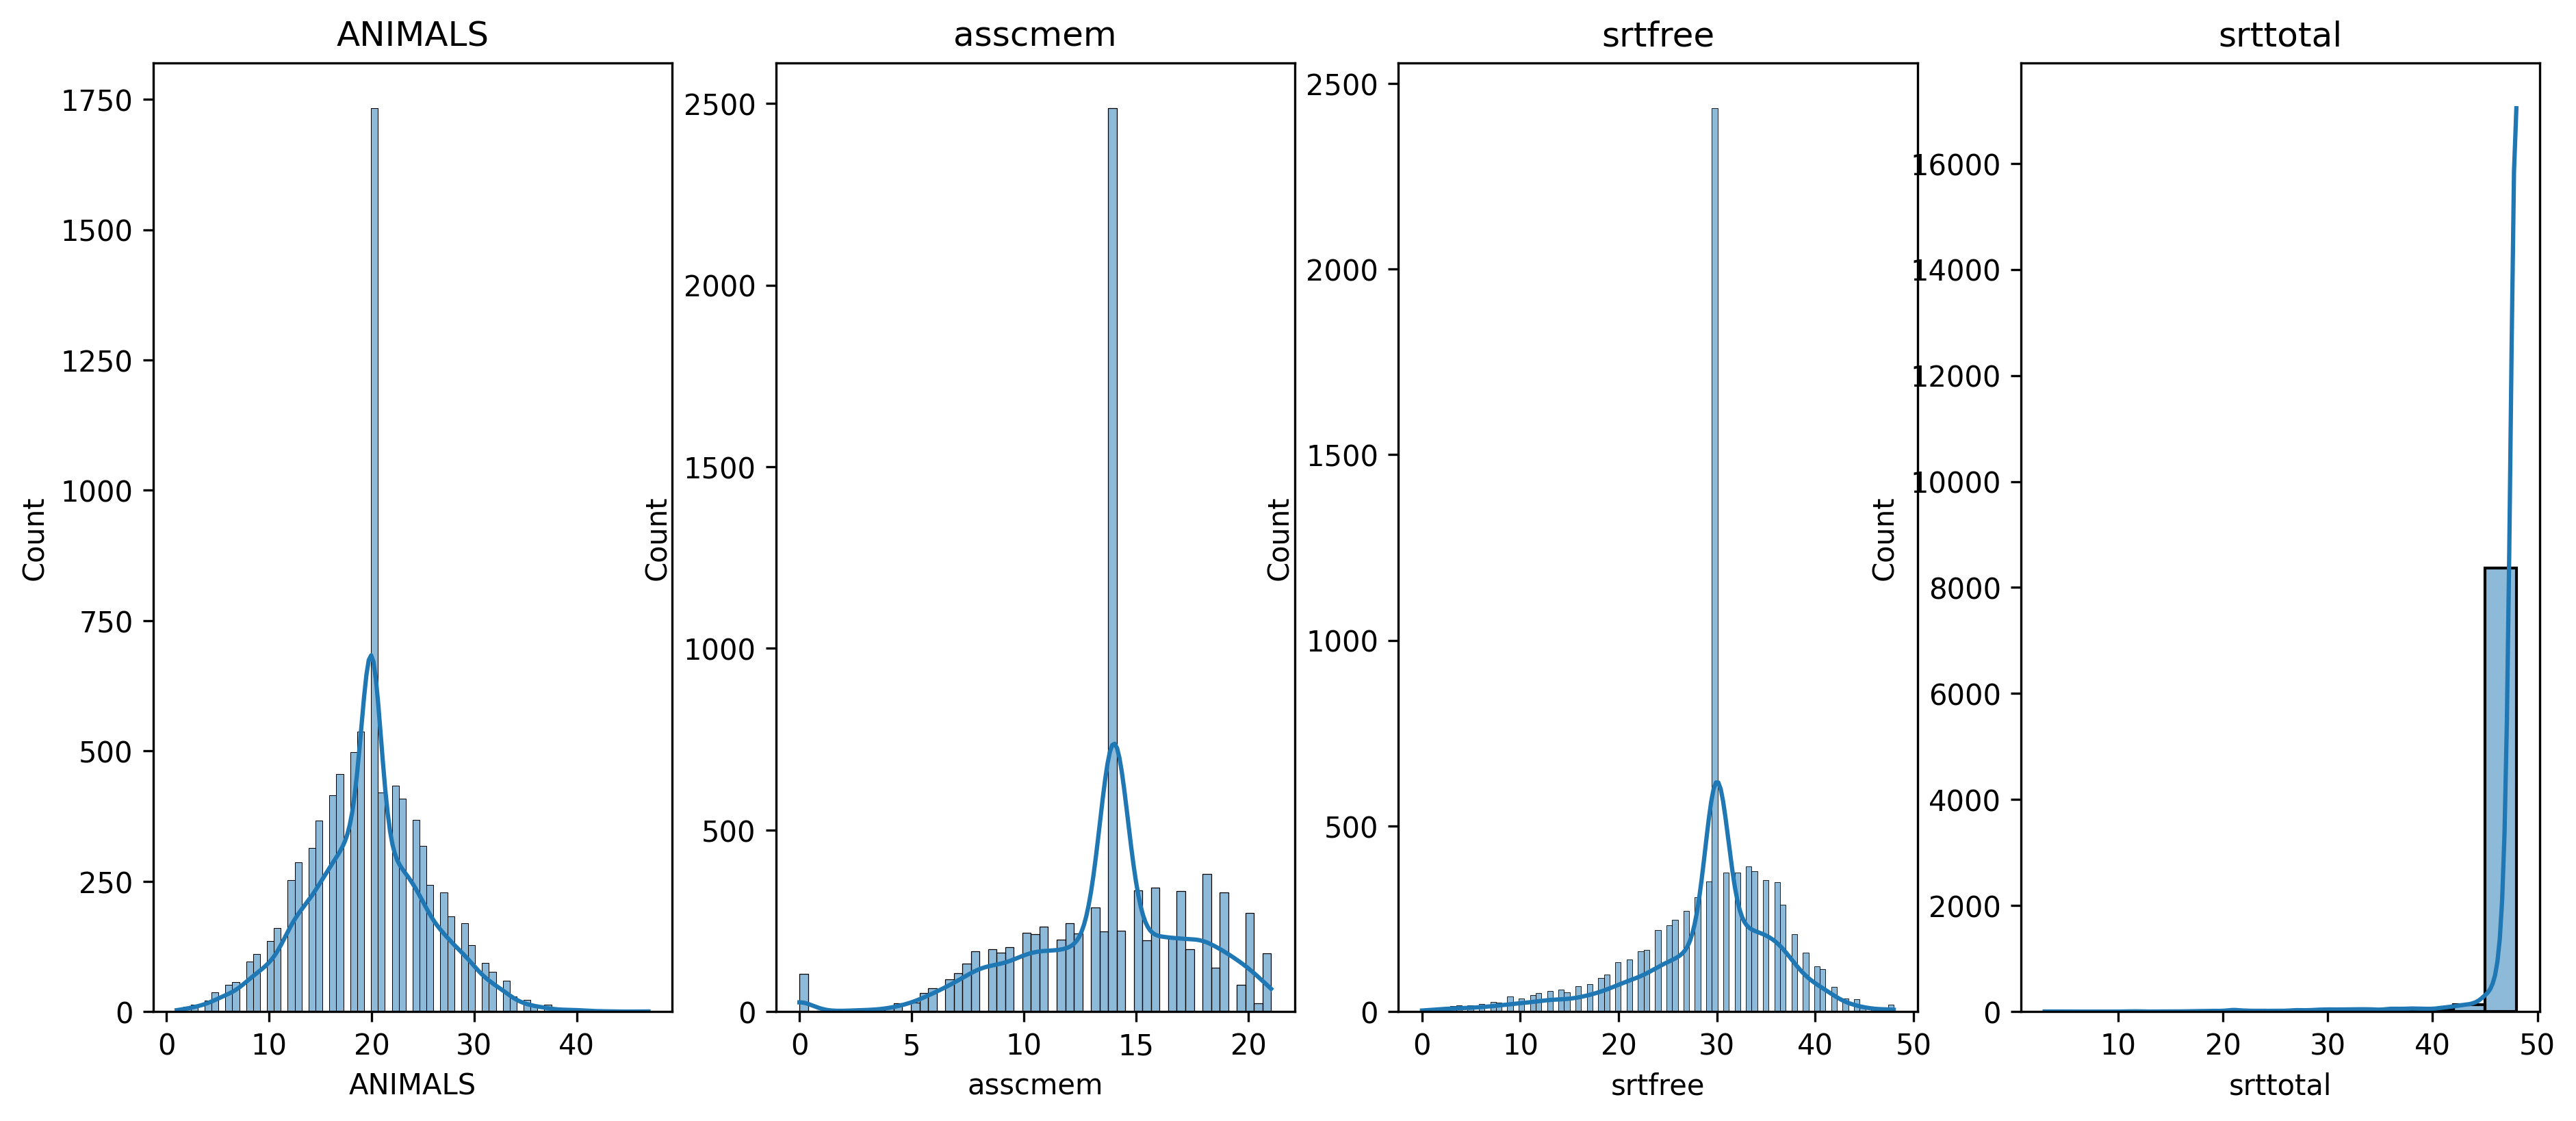

<Figure size 640x480 with 0 Axes>

In [19]:
fig,axes=plt.subplots(1,4,figsize=(15,6),dpi=300)

for i,col in enumerate(ilk_dort):
    sns.histplot(data=df[col],kde=True,ax=axes[i])
    axes[i].set_title(col)

plt.show()
plt.tight_layout()

In [20]:
ikinci_sekiz=float_cols[4:12:]

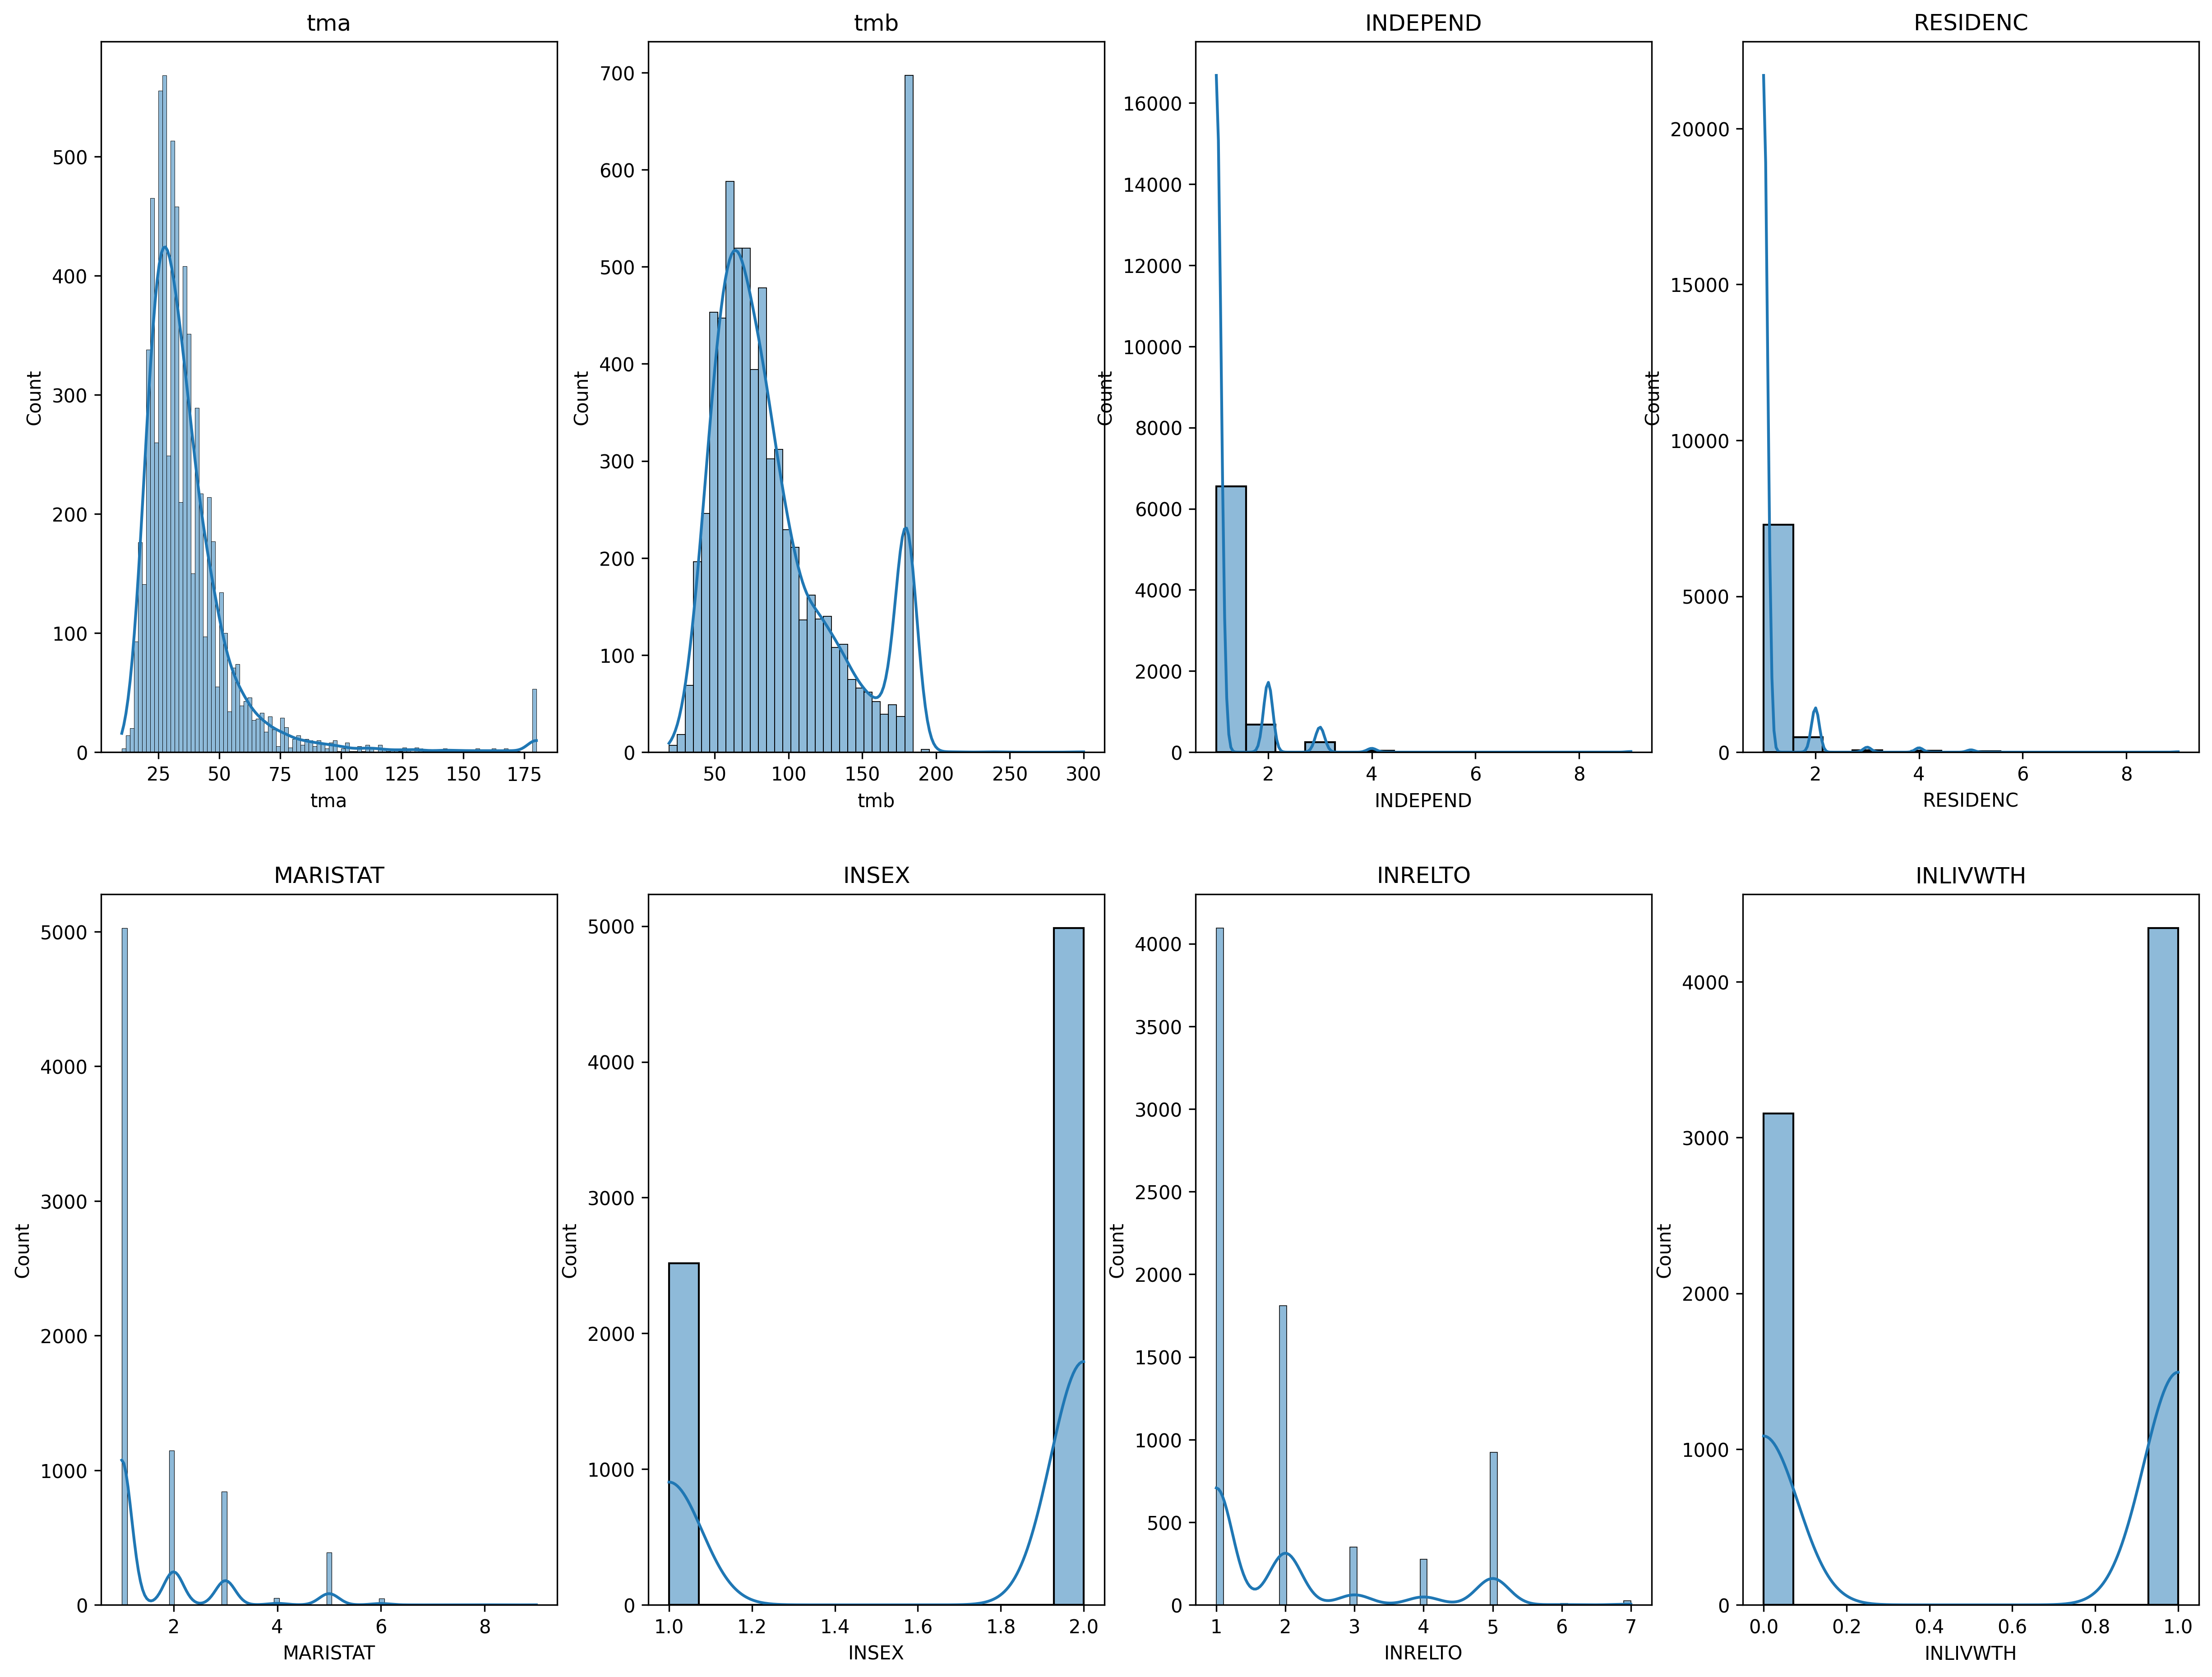

<Figure size 640x480 with 0 Axes>

In [21]:
fig,axes=plt.subplots(2,4,figsize=(20,15),dpi=300)
axes = axes.flatten()
for i,col in enumerate(ikinci_sekiz):
    sns.histplot(data=df[col],kde=True,ax=axes[i])
    axes[i].set_title(col)

plt.show()
plt.tight_layout()

In [22]:
#SOLA VEYA SAĞA KUYRUKLU GRAFİKLERDE MEDİAN İLE EKSİK VERİ DOLDURMA YÖNTEMİ KULLANDIK
#NORMAL DAĞILIM OLAN GRAFİKLERRDE MEAN VEYA KNN YÖNTEMİ
#İKİLİ TEPESİ BARİZ OLAN YUKARDAKİ TMB ÖRNEĞİ GİBİ GRAFİKLERDE KNN YÖNTEMİ DAHA GÜVENİLİR OLDU
#INDEPEND,RESIDENC GİBİ TEK BİR DEĞERİN YOĞUNLUKTA OLDUGU KISIMLARI İSE MOD İLE DOLDURMA İŞLEMİ YAPILACAK

In [23]:
sag_carpik=['tma'] #median
ikili_tepe=['tmb'] #ikili tepe
mod=['INDEPEND','RESIDENC','MARISTAT','INSEX','INRELTO','INLIVWTH'] #mod

In [24]:
imputer_knn=KNNImputer(n_neighbors=4)
mod_imputer=SimpleImputer(strategy='most_frequent')
mean_imputer=SimpleImputer(strategy='mean')
median_imputer=SimpleImputer(strategy='median')

In [25]:
df[sag_carpik]=median_imputer.fit_transform(df[sag_carpik])

In [26]:
df[ikili_tepe]=imputer_knn.fit_transform(df[ikili_tepe])
df[ikili_tepe] = df[ikili_tepe].round().astype(int)

In [27]:
for col in mod:
    df[col]=mod_imputer.fit_transform(df[[col]])

In [28]:
ucuncu_sekiz=float_cols[12:20:]

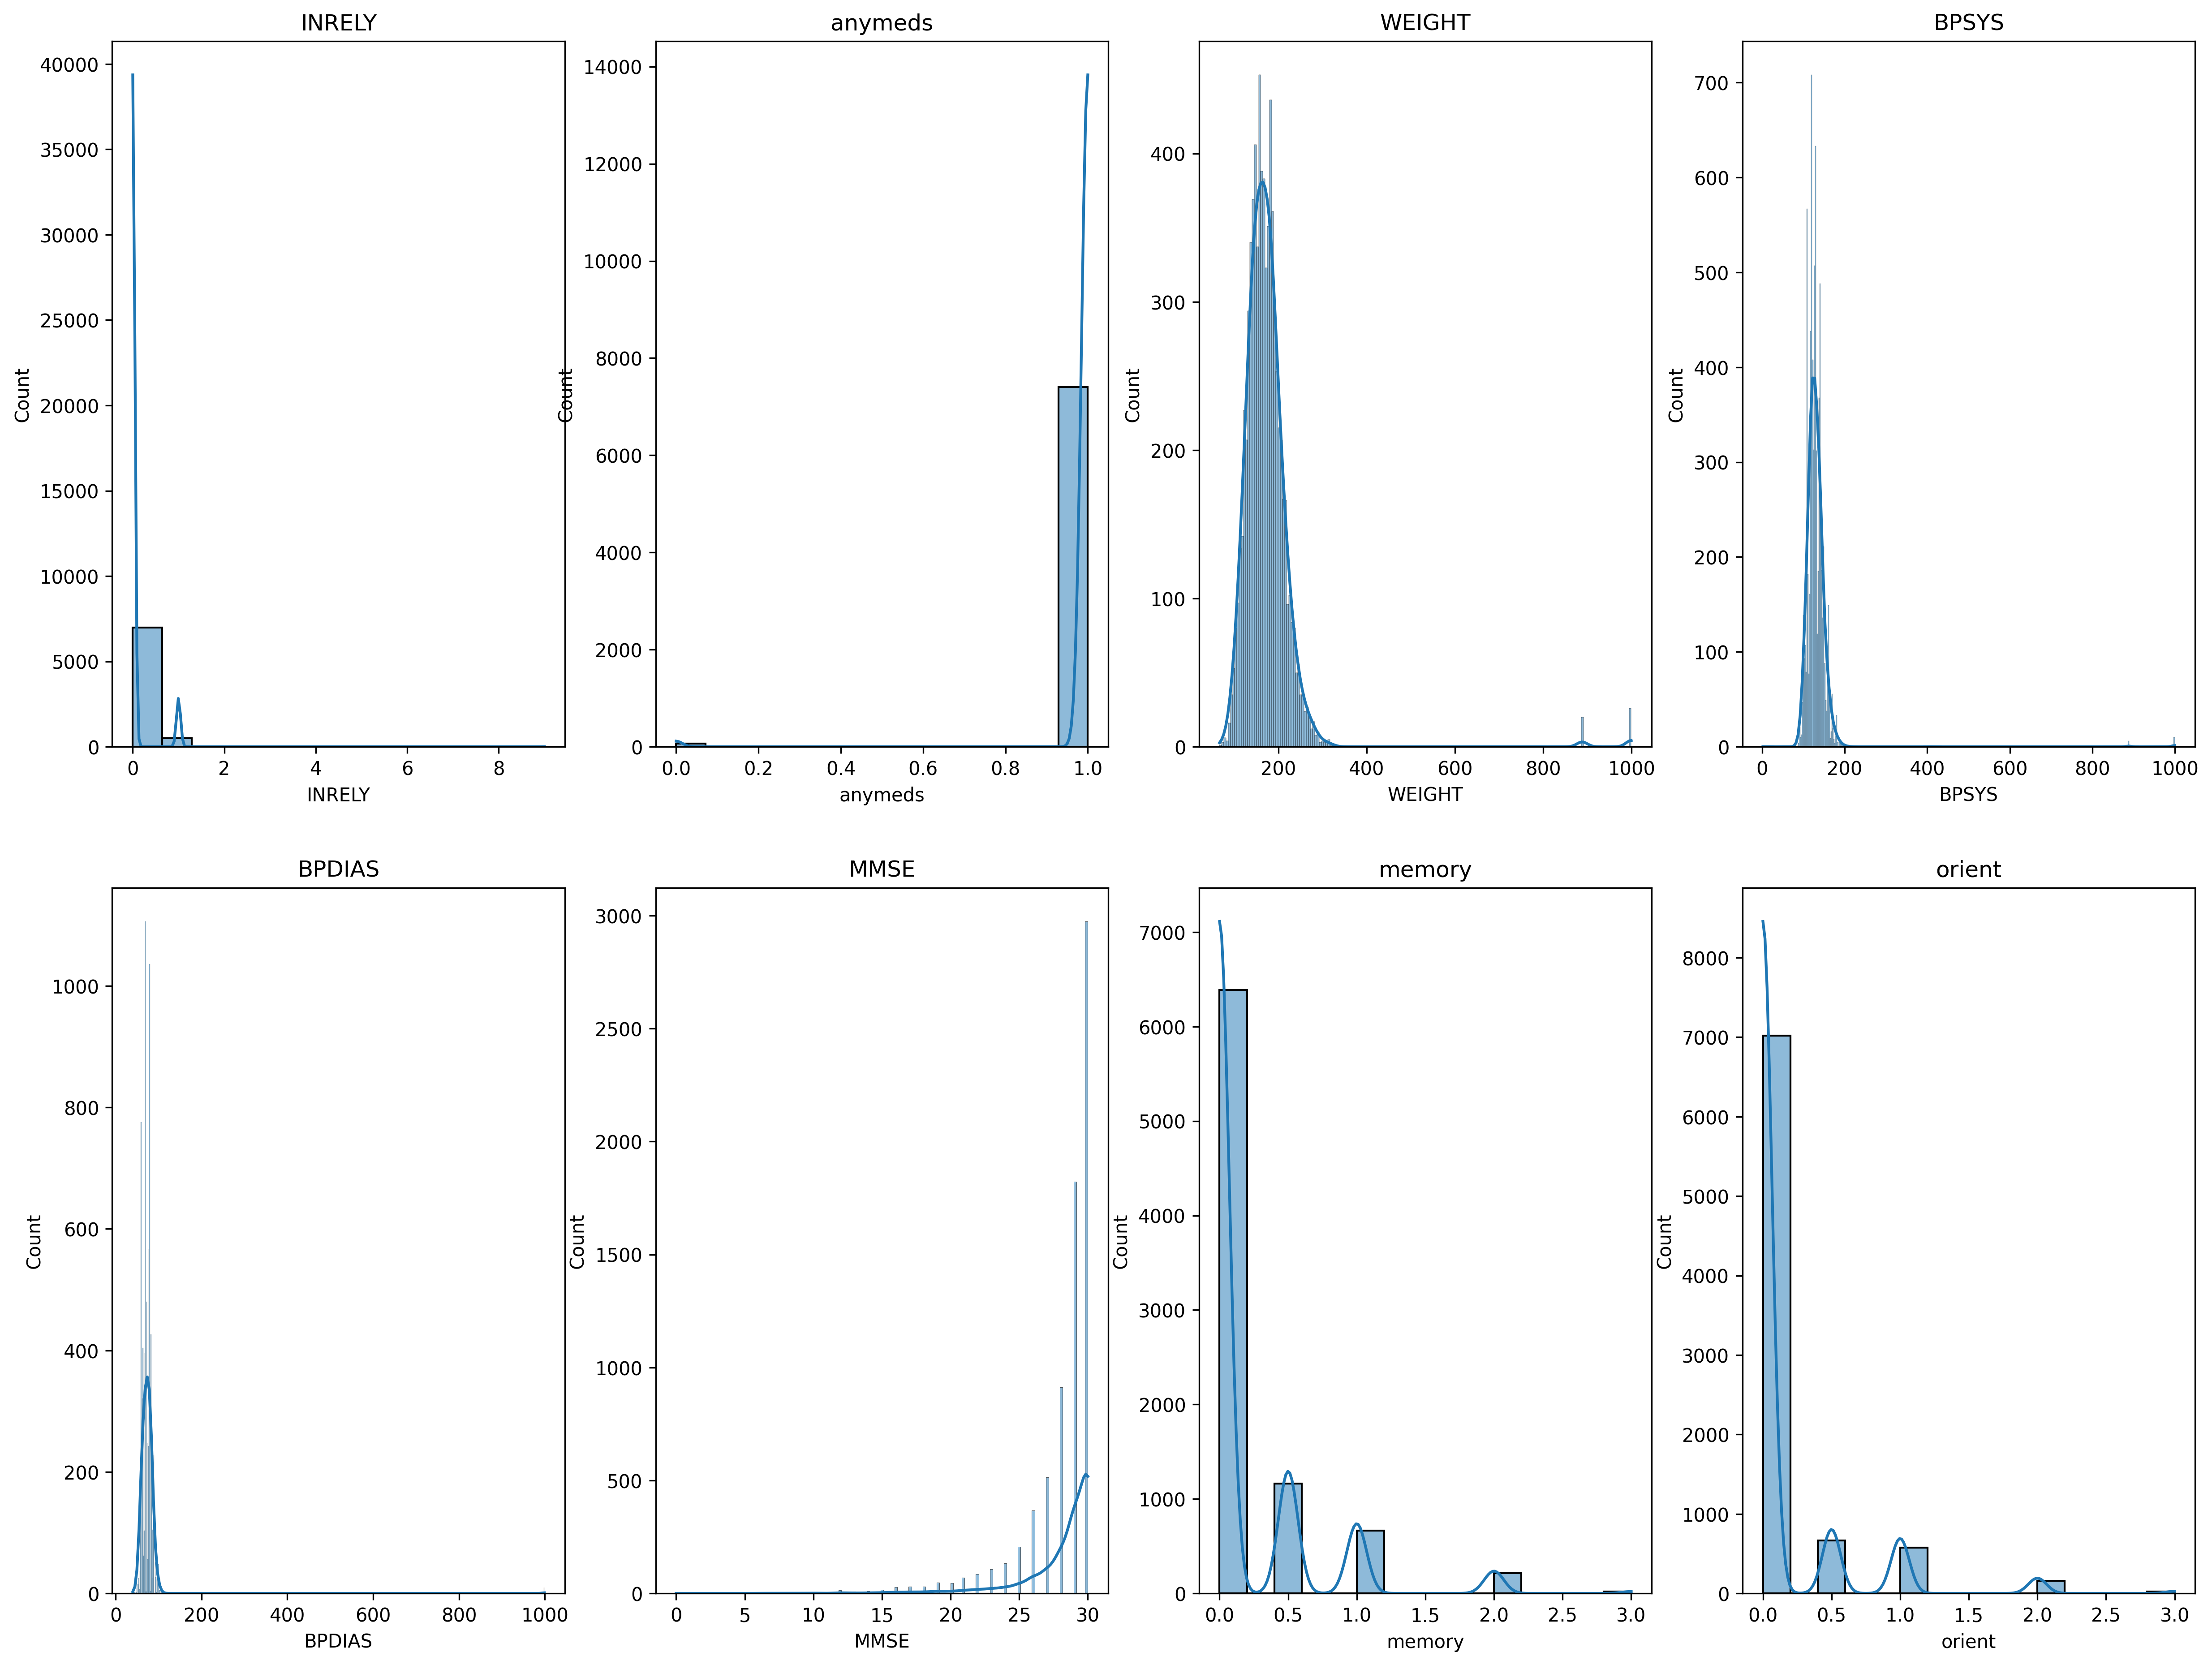

<Figure size 640x480 with 0 Axes>

In [29]:
fig,axes=plt.subplots(2,4,figsize=(20,15),dpi=300)
axes = axes.flatten()
for i,col in enumerate(ucuncu_sekiz):
    sns.histplot(data=df[col],kde=True,ax=axes[i])
    axes[i].set_title(col)

plt.show()
plt.tight_layout()

In [30]:

grafik_dagilim={'kuyruklu':['MMSE','WEIGHT'],'normal_dagilim':['BPSYS','BPDIAS'],'mod_':['INRELY','anymeds','memory','orient']}

In [31]:
for key,value in grafik_dagilim.items():
    if key=='kuyruklu':
        df[value]=median_imputer.fit_transform(df[value])
    elif key=='normal_dagilim':
        df[value]=mean_imputer.fit_transform(df[value])
    else:
        df[value]=mod_imputer.fit_transform(df[value])

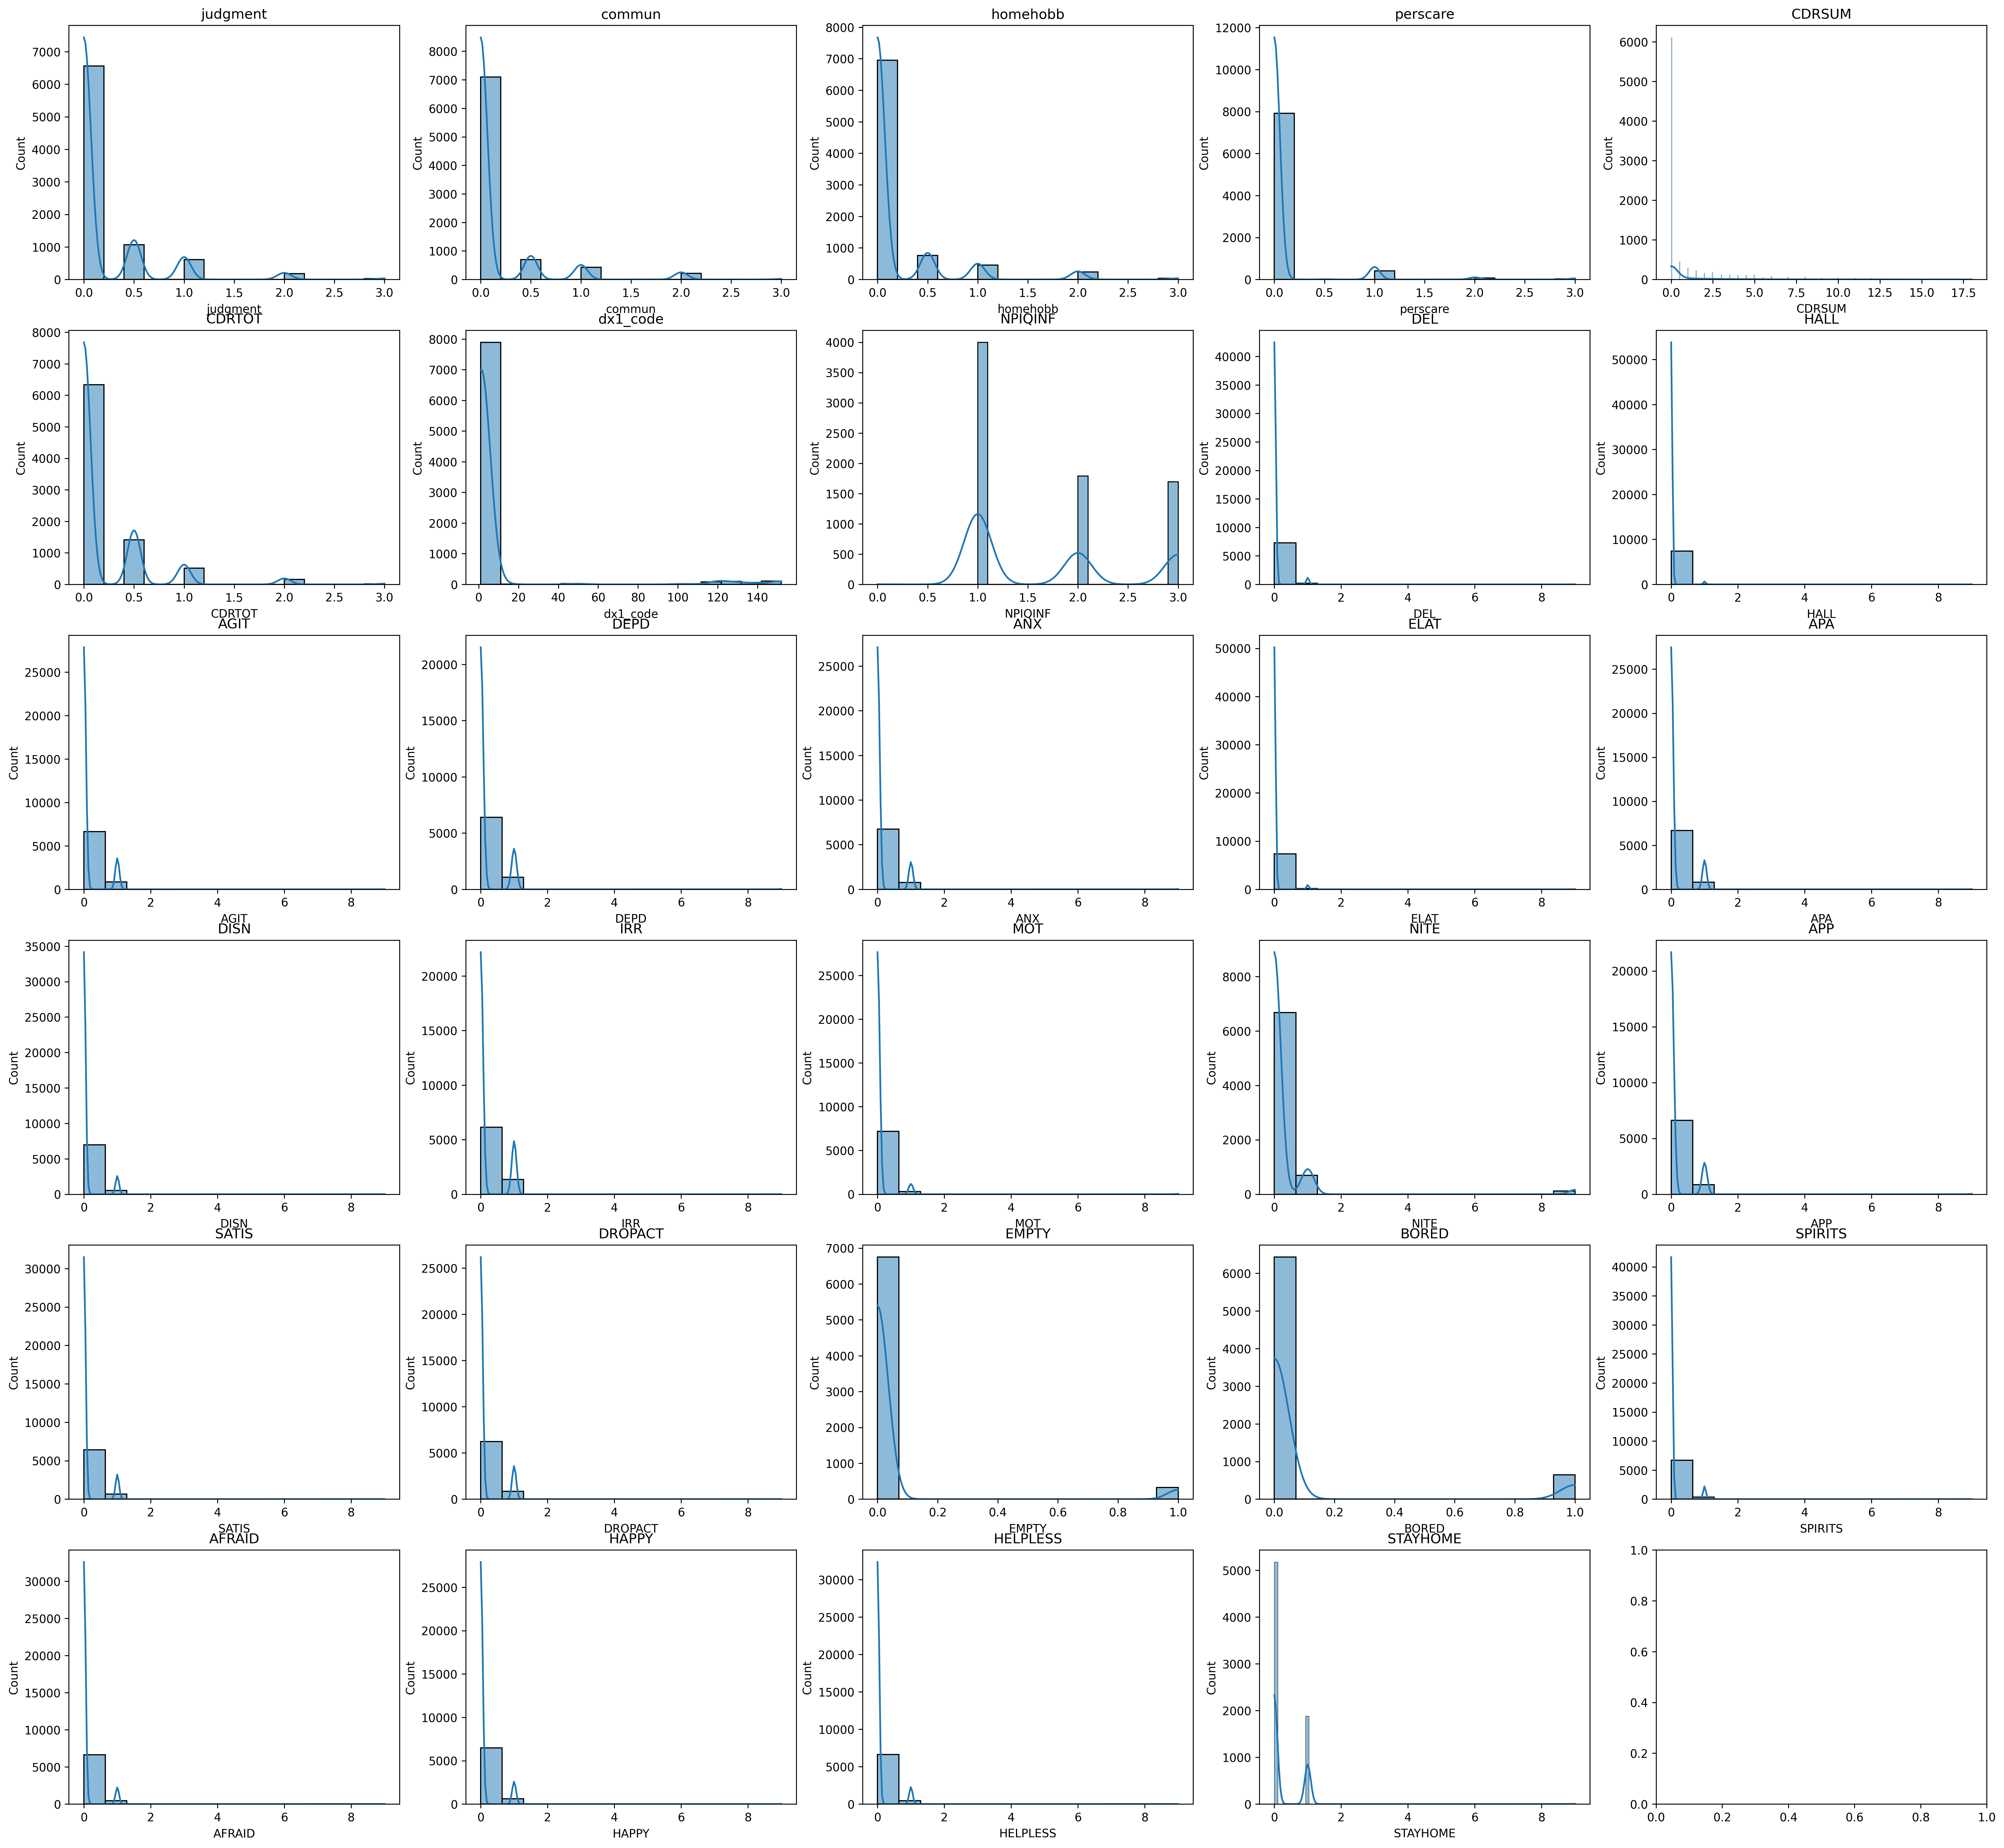

<Figure size 640x480 with 0 Axes>

In [32]:
kalan_grafikler=float_cols[20:49:]
fig,axes=plt.subplots(6,5,figsize=(30,28),dpi=300)
axes = axes.flatten()
for i,col in enumerate(kalan_grafikler):
    sns.histplot(data=df[col],kde=True,ax=axes[i])
    axes[i].set_title(col)

plt.show()

plt.tight_layout()


In [33]:
#KALAN GRAFİKLERİN ÇOĞU TEK DEĞERDE TOPLANDIĞI İÇİN YA DA İKİLİ TEPE OLUŞTURDUĞU İÇİN KNN IMPUTER KULLANILDI

In [34]:
for col in kalan_grafikler:
    df[col]=imputer_knn.fit_transform(df[[col]])
    df[col] = df[col].round().astype(int)

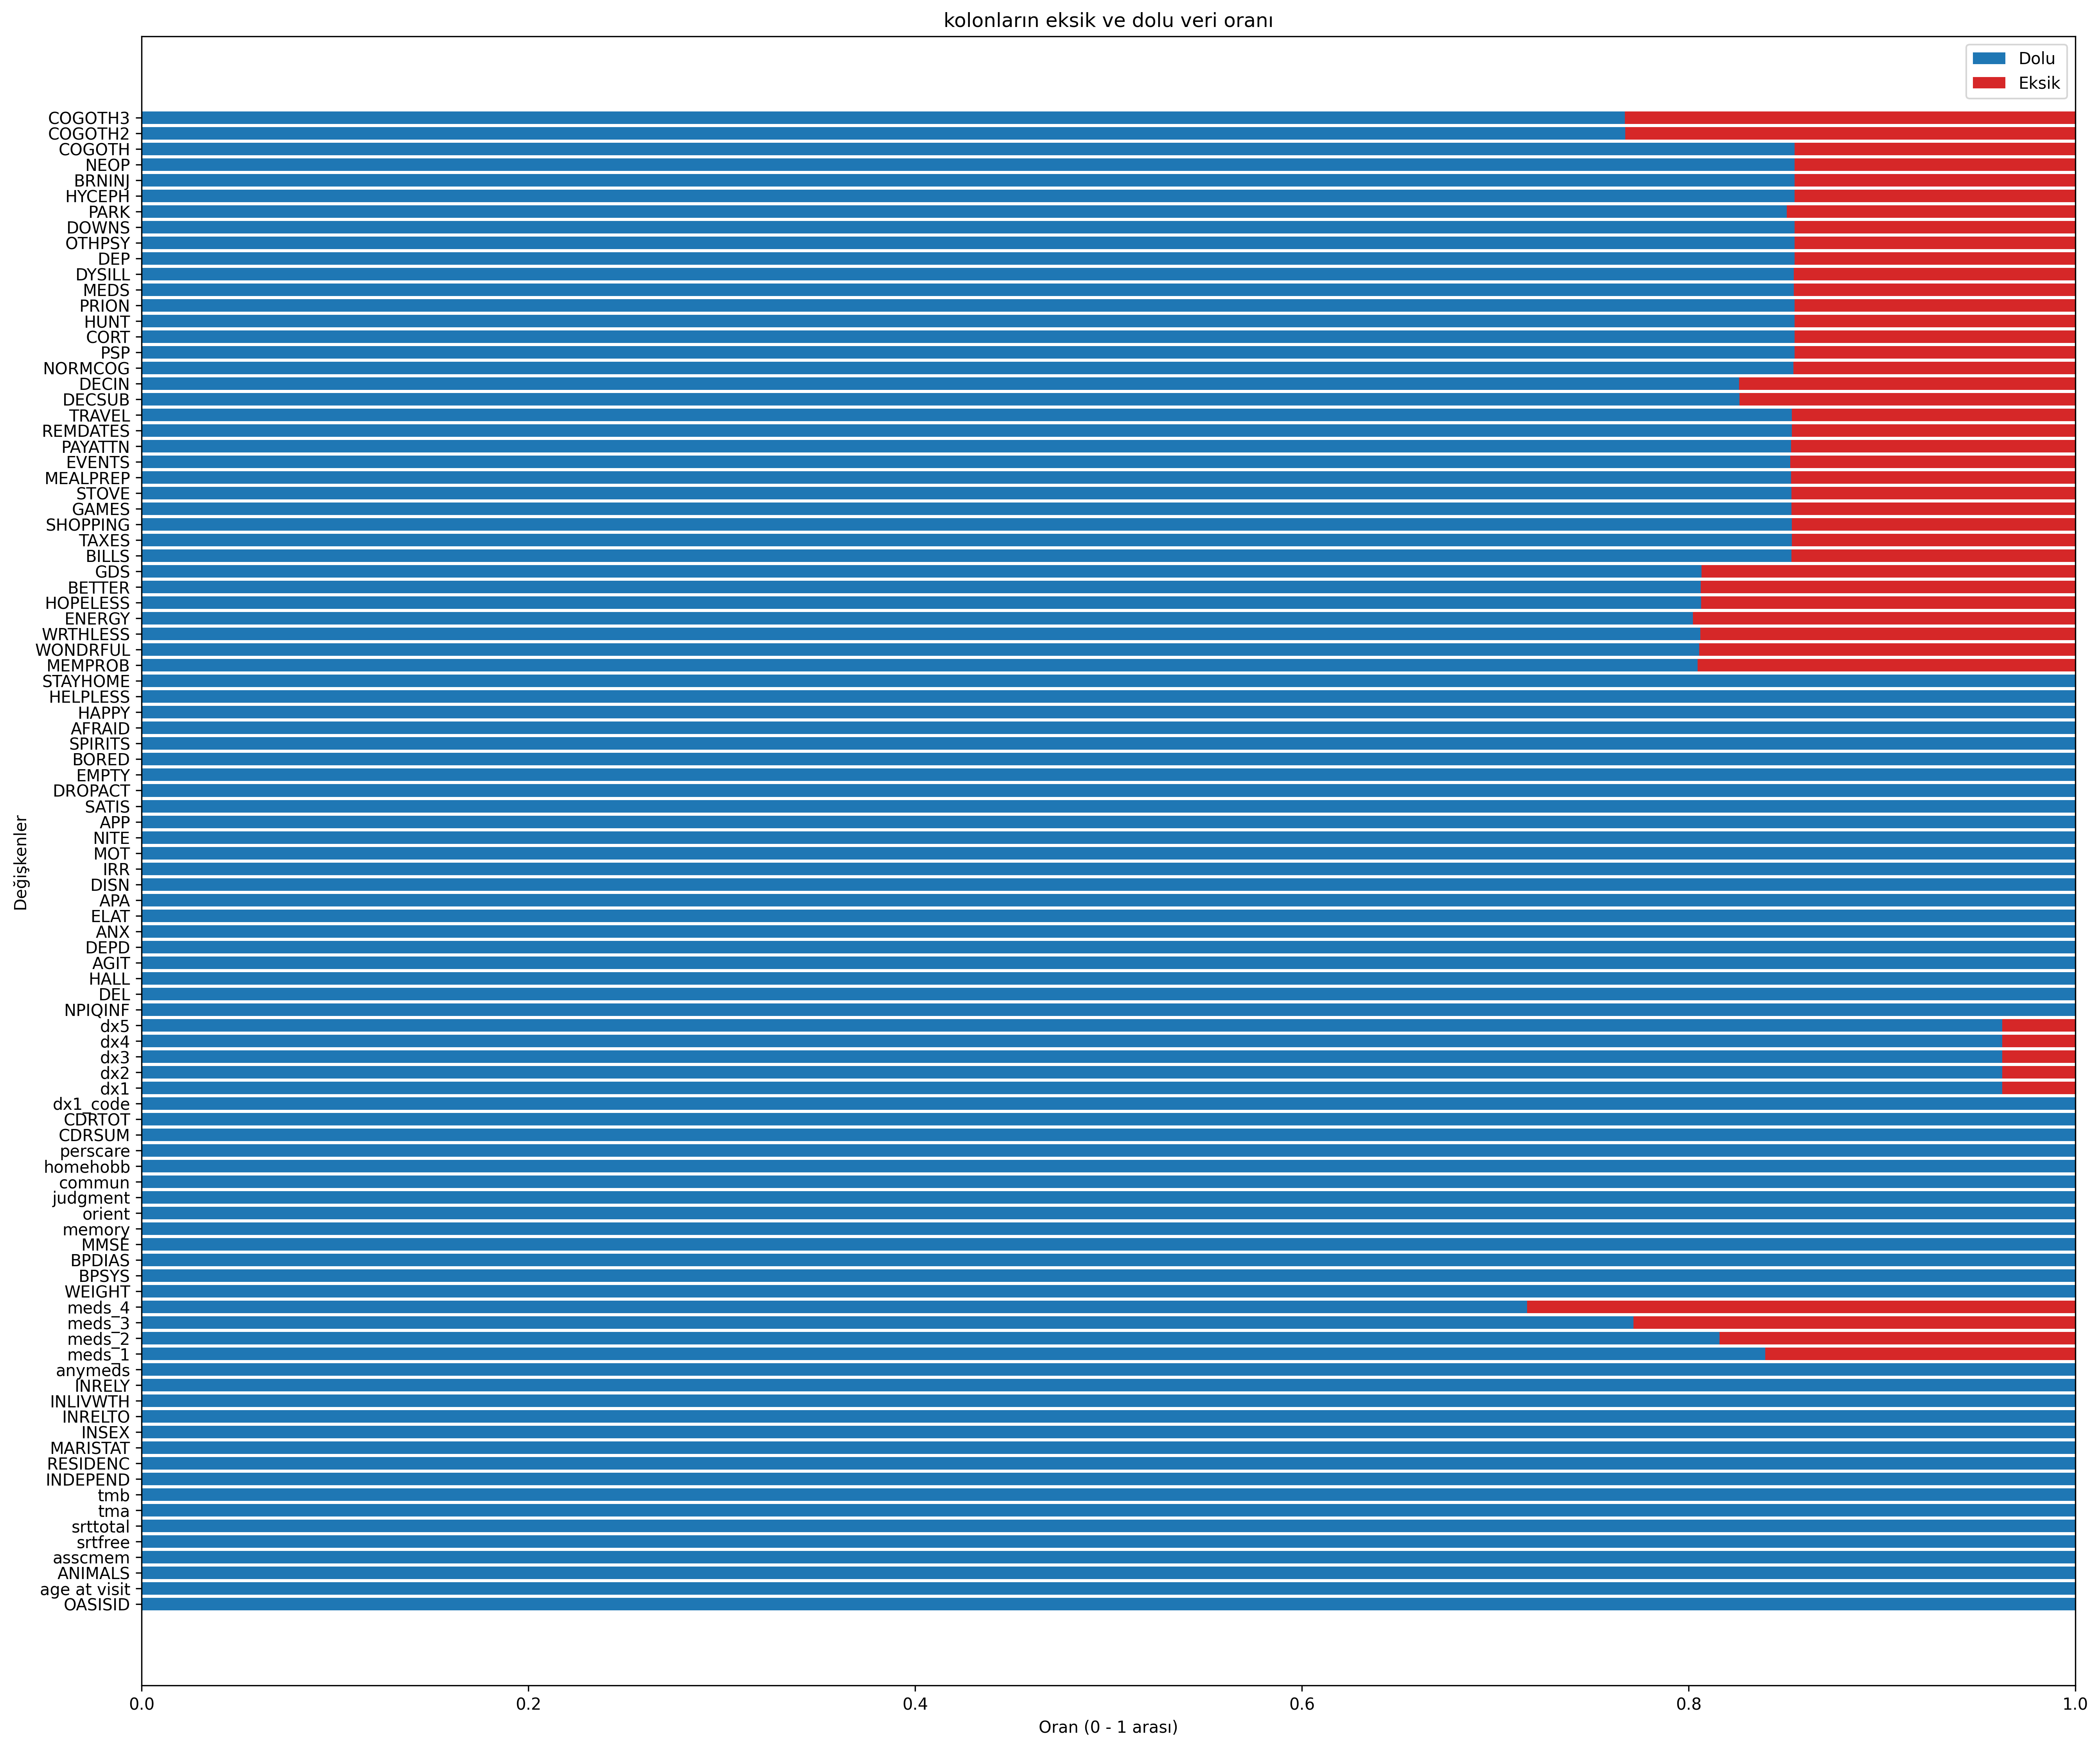

In [35]:


visualize_all()


In [36]:
#BURAYA KADAR SAYISAL KOLONLARIN EKSİK VERİLERİNİ TAMAMLADIK ŞİMDİ KATREGORİKLERE BAKALIM

In [37]:
cat_cols=[col for col in df.columns if df[col].dtype=='O']

In [38]:
cat_cols.remove('OASISID')

In [39]:
cat_cols

['meds_1', 'meds_2', 'meds_3', 'meds_4', 'dx1', 'dx2', 'dx3', 'dx4', 'dx5']

In [40]:
df['meds_2'].unique()

array(['ASA', 'lisinopril', 'amlodipine', ..., 'Celecoxib', 'Proair HFA',
       'Losartan/Hctz'], shape=(1450,), dtype=object)

In [41]:
df['meds_1'].unique()

array(['LISINOPR', 'aspirin', 'Lisinopril', ..., 'Telmisartan', 'aleve',
       'Potassium (OTC)'], shape=(1299,), dtype=object)

In [42]:
df['meds_3'].unique()

array(['CALCIUM', 'calcium-vitamin D', 'lisinopril', ...,
       'Cholecalciferol', 'zestoretic', 'cerovite senior MVI'],
      shape=(1452,), dtype=object)

In [43]:
for col in cat_cols:
    df[col]=df[col].str.lower()

In [44]:
df['all_meds'] = (
    df[['meds_1','meds_2','meds_3','meds_4']]
    .apply(lambda x: ', '.join(sorted(set(x.dropna().astype(str)))), axis=1)
)

In [45]:
df['all_meds'].value_counts().sum()

np.int64(8777)

In [46]:
df_clean=df.copy()

In [47]:
df_clean.drop(['meds_1','meds_2','meds_3','meds_4'],axis=1,inplace=True)

In [48]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8777 entries, 0 to 8776
Data columns (total 93 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   OASISID       8777 non-null   object 
 1   age at visit  8777 non-null   int64  
 2   ANIMALS       8777 non-null   int64  
 3   asscmem       8777 non-null   float64
 4   srtfree       8777 non-null   float64
 5   srttotal      8777 non-null   float64
 6   tma           8777 non-null   float64
 7   tmb           8777 non-null   int64  
 8   INDEPEND      8777 non-null   float64
 9   RESIDENC      8777 non-null   float64
 10  MARISTAT      8777 non-null   float64
 11  INSEX         8777 non-null   float64
 12  INRELTO       8777 non-null   float64
 13  INLIVWTH      8777 non-null   float64
 14  INRELY        8777 non-null   float64
 15  anymeds       8777 non-null   float64
 16  WEIGHT        8777 non-null   float64
 17  BPSYS         8777 non-null   float64
 18  BPDIAS        8777 non-null 

In [49]:
import pandas as pd
import numpy as np
import os 
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
# df = pd.read_csv("merged_dataset.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8777 entries, 0 to 8776
Data columns (total 97 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   OASISID       8777 non-null   object 
 1   age at visit  8777 non-null   int64  
 2   ANIMALS       8777 non-null   int64  
 3   asscmem       8777 non-null   float64
 4   srtfree       8777 non-null   float64
 5   srttotal      8777 non-null   float64
 6   tma           8777 non-null   float64
 7   tmb           8777 non-null   int64  
 8   INDEPEND      8777 non-null   float64
 9   RESIDENC      8777 non-null   float64
 10  MARISTAT      8777 non-null   float64
 11  INSEX         8777 non-null   float64
 12  INRELTO       8777 non-null   float64
 13  INLIVWTH      8777 non-null   float64
 14  INRELY        8777 non-null   float64
 15  anymeds       8777 non-null   float64
 16  meds_1        7370 non-null   object 
 17  meds_2        7162 non-null   object 
 18  meds_3        6771 non-null 

In [51]:
df.describe()

,age at visit,ANIMALS,asscmem,srtfree,srttotal,tma,tmb,INDEPEND,RESIDENC,MARISTAT,...,DEP,OTHPSY,DOWNS,PARK,HYCEPH,BRNINJ,NEOP,COGOTH,COGOTH2,COGOTH3
count,8777.000000,8777.000000,8777.000000,8777.000000,8777.000000,8777.000000,8777.000000,8777.000000,8777.000000,8777.000000,...,7503.000000,7503.000000,7502.0,7467.000000,7502.000000,7502.000000,7502.000000,7502.000000,6734.000000,6733.000000
mean,73.793551,19.641677,13.713683,29.295545,47.243022,36.002051,91.742851,1.150507,1.097869,1.547681,...,0.158203,0.005998,0.0,0.012187,0.000533,0.010930,0.000933,0.027859,0.002822,0.000446
std,8.684403,5.782562,3.806465,7.125961,3.229885,19.127606,37.298829,0.496820,0.438690,1.064911,...,0.364956,0.077217,0.0,0.109727,0.023086,0.103983,0.030534,0.164580,0.053047,0.021105
min,-48.000000,1.000000,0.000000,0.000000,3.000000,10.000000,19.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,69.000000,16.000000,12.000000,27.000000,48.000000,27.000000,65.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,74.000000,20.000000,14.000000,30.000000,48.000000,32.000000,92.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,79.000000,23.000000,16.000000,33.000000,48.000000,38.000000,99.000000,1.000000,1.000000,2.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,100.000000,47.000000,21.000000,48.000000,48.000000,180.000000,300.000000,9.000000,9.000000,9.000000,...,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [52]:
df.shape

(8777, 97)

In [53]:

df.columns

Index(['OASISID', 'age at visit', 'ANIMALS', 'asscmem', 'srtfree', 'srttotal',
       'tma', 'tmb', 'INDEPEND', 'RESIDENC', 'MARISTAT', 'INSEX', 'INRELTO',
       'INLIVWTH', 'INRELY', 'anymeds', 'meds_1', 'meds_2', 'meds_3', 'meds_4',
       'WEIGHT', 'BPSYS', 'BPDIAS', 'MMSE', 'memory', 'orient', 'judgment',
       'commun', 'homehobb', 'perscare', 'CDRSUM', 'CDRTOT', 'dx1_code', 'dx1',
       'dx2', 'dx3', 'dx4', 'dx5', 'NPIQINF', 'DEL', 'HALL', 'AGIT', 'DEPD',
       'ANX', 'ELAT', 'APA', 'DISN', 'IRR', 'MOT', 'NITE', 'APP', 'SATIS',
       'DROPACT', 'EMPTY', 'BORED', 'SPIRITS', 'AFRAID', 'HAPPY', 'HELPLESS',
       'STAYHOME', 'MEMPROB', 'WONDRFUL', 'WRTHLESS', 'ENERGY', 'HOPELESS',
       'BETTER', 'GDS', 'BILLS', 'TAXES', 'SHOPPING', 'GAMES', 'STOVE',
       'MEALPREP', 'EVENTS', 'PAYATTN', 'REMDATES', 'TRAVEL', 'DECSUB',
       'DECIN', 'NORMCOG', 'PSP', 'CORT', 'HUNT', 'PRION', 'MEDS', 'DYSILL',
       'DEP', 'OTHPSY', 'DOWNS', 'PARK', 'HYCEPH', 'BRNINJ', 'NEOP', 'COGOTH',
  

In [54]:
len(df.columns)

97

In [55]:
len(df.describe().columns) # numerik sütun sayısı 

86

In [56]:
df.describe().columns # numerik kolonlar

Index(['age at visit', 'ANIMALS', 'asscmem', 'srtfree', 'srttotal', 'tma',
       'tmb', 'INDEPEND', 'RESIDENC', 'MARISTAT', 'INSEX', 'INRELTO',
       'INLIVWTH', 'INRELY', 'anymeds', 'WEIGHT', 'BPSYS', 'BPDIAS', 'MMSE',
       'memory', 'orient', 'judgment', 'commun', 'homehobb', 'perscare',
       'CDRSUM', 'CDRTOT', 'dx1_code', 'NPIQINF', 'DEL', 'HALL', 'AGIT',
       'DEPD', 'ANX', 'ELAT', 'APA', 'DISN', 'IRR', 'MOT', 'NITE', 'APP',
       'SATIS', 'DROPACT', 'EMPTY', 'BORED', 'SPIRITS', 'AFRAID', 'HAPPY',
       'HELPLESS', 'STAYHOME', 'MEMPROB', 'WONDRFUL', 'WRTHLESS', 'ENERGY',
       'HOPELESS', 'BETTER', 'GDS', 'BILLS', 'TAXES', 'SHOPPING', 'GAMES',
       'STOVE', 'MEALPREP', 'EVENTS', 'PAYATTN', 'REMDATES', 'TRAVEL',
       'DECSUB', 'DECIN', 'NORMCOG', 'PSP', 'CORT', 'HUNT', 'PRION', 'MEDS',
       'DYSILL', 'DEP', 'OTHPSY', 'DOWNS', 'PARK', 'HYCEPH', 'BRNINJ', 'NEOP',
       'COGOTH', 'COGOTH2', 'COGOTH3'],
      dtype='object')

In [57]:
for col in df.columns:  # kolonların  kaç tane farklı değerde olduğu 
    print(col, df[col].nunique())
   


OASISID 1378
age at visit 59
ANIMALS 44
asscmem 42
srtfree 49
srttotal 39
tma 143
tmb 166
INDEPEND 5
RESIDENC 6
MARISTAT 8
INSEX 2
INRELTO 7
INLIVWTH 2
INRELY 3
anymeds 2
meds_1 1044
meds_2 1167
meds_3 1173
meds_4 1185
WEIGHT 644
BPSYS 99
BPDIAS 61
MMSE 29
memory 5
orient 5
judgment 4
commun 4
homehobb 4
perscare 4
CDRSUM 19
CDRTOT 4
dx1_code 40
dx1 54
dx2 72
dx3 50
dx4 32
dx5 22
NPIQINF 4
DEL 3
HALL 3
AGIT 3
DEPD 3
ANX 3
ELAT 4
APA 3
DISN 3
IRR 3
MOT 3
NITE 3
APP 3
SATIS 3
DROPACT 4
EMPTY 2
BORED 2
SPIRITS 3
AFRAID 3
HAPPY 3
HELPLESS 3
STAYHOME 3
MEMPROB 3
WONDRFUL 3
WRTHLESS 3
ENERGY 3
HOPELESS 3
BETTER 3
GDS 15
BILLS 6
TAXES 6
SHOPPING 6
GAMES 6
STOVE 6
MEALPREP 6
EVENTS 6
PAYATTN 6
REMDATES 6
TRAVEL 6
DECSUB 4
DECIN 3
NORMCOG 2
PSP 2
CORT 2
HUNT 1
PRION 1
MEDS 2
DYSILL 2
DEP 2
OTHPSY 2
DOWNS 1
PARK 2
HYCEPH 2
BRNINJ 2
NEOP 2
COGOTH 2
COGOTH2 2
COGOTH3 2
all_meds 6291


In [58]:
# for col in df.columns:
#     values = []
    
#     # numerik olmayanlar -> kategorik
#     if col not in df.describe().columns:
#         for val in df[col].unique():
#             values.append(val)
        
#         print("{0} -> {1}".format(col, values))

In [59]:
dependent_variable = df.memory
dependent_variable.info()

<class 'pandas.core.series.Series'>
RangeIndex: 8777 entries, 0 to 8776
Series name: memory
Non-Null Count  Dtype  
--------------  -----  
8777 non-null   float64
dtypes: float64(1)
memory usage: 68.7 KB


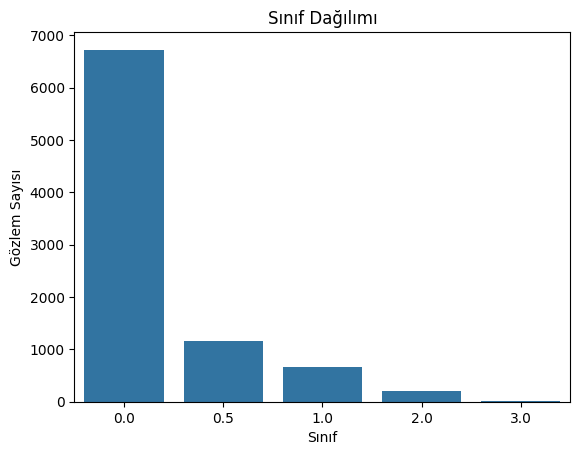

In [60]:
sns.countplot(x=dependent_variable)
plt.title("Sınıf Dağılımı")
plt.xlabel("Sınıf")
plt.ylabel("Gözlem Sayısı")
plt.show()


In [61]:
def visualize_counts(x,y,cols):
    fig,axes=plt.subplots(2,4,figsize=(20,12))
    for ax, col in zip(axes.flat, cols):
        sns.histplot(data=df[col],kde=True,ax=ax)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()
    

In [62]:
def visualize_boxPlot(x,y,cols):
    fig,axes = plt.subplots(x,y,figsize=(20,12))
    for ax, col in zip(axes.flat, cols):
        sns.boxplot(data=df[col], ax=ax)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()
    

In [63]:
def visualize_nullValue(x,y,cols):
    fig,axes = plt.subplots(x,y,figsize=(20,12))
    for ax,col in zip(axes.flat,cols):
        mean = 100-df[col].isnull().mean()*100
        status = df[col].isnull().map({True: 'Boş', False: 'Dolu'})
        sns.countplot(x=status, ax=ax)
        ax.set_title(col)
        ax.set_xlabel('')
        ax.set_ylabel('Adet')
        ax.set_title(col)
        ax.text(0.6, 0.97, f'%{mean:.1f} Dolu', 
            transform=ax.transAxes, ha='center', va='center', 
            fontsize=12, fontweight='bold')
        
    plt.tight_layout()
    plt.show()
    
    


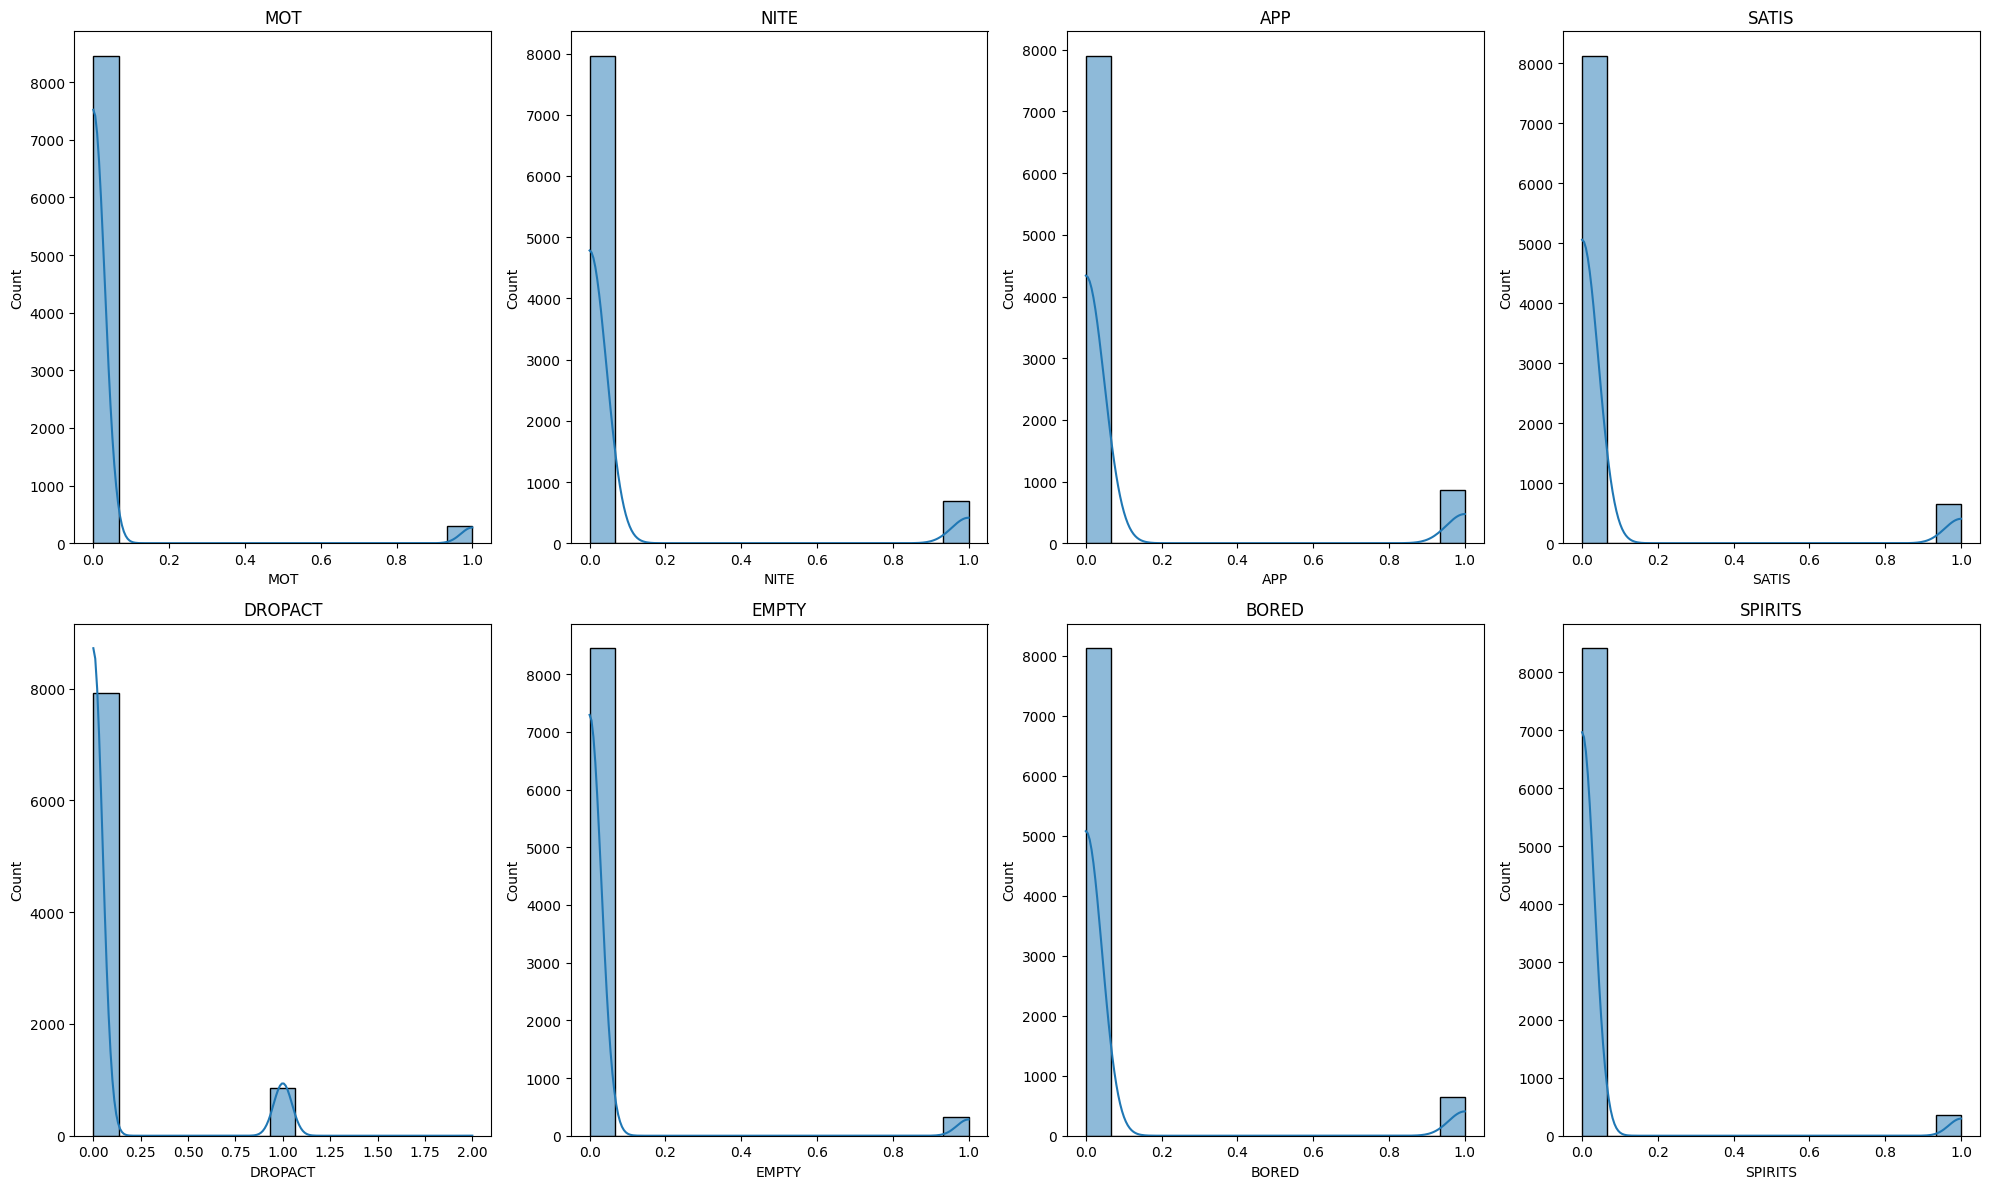

In [64]:
cols = df.iloc[:,48:56]
for col in cols:
    df[col] = df[col].replace(9, np.nan) 
visualize_counts(2,4,cols=cols)



In [65]:
for col in cols:
    print(df[col].value_counts())

MOT
0.0    8459
1.0     307
Name: count, dtype: int64
NITE
0.0    7965
1.0     694
Name: count, dtype: int64
APP
0.0    7904
1.0     862
Name: count, dtype: int64
SATIS
0.0    8122
1.0     654
Name: count, dtype: int64
DROPACT
0.0    7921
1.0     853
2.0       1
Name: count, dtype: int64
EMPTY
0    8450
1     327
Name: count, dtype: int64
BORED
0    8128
1     649
Name: count, dtype: int64
SPIRITS
0.0    8419
1.0     357
Name: count, dtype: int64


In [66]:
df["DROPACT"] = df["DROPACT"].replace(2, np.nan) # Olmaması gereken bir değerdi

In [67]:
# visualize_boxPlot(2,4,cols=cols)

In [68]:
from sklearn.impute import SimpleImputer,KNNImputer

def knn_Imputer(cols,neighbors):
    imputer = KNNImputer(n_neighbors=neighbors)    
    for col in cols:
        df[col]=imputer.fit_transform(df[[col]])
    df[cols] = df[cols].round().astype(int)
    return df[cols]
def simple_Imputer(cols,value):
    imputer = SimpleImputer(missing_values=np.nan,strategy=value)    
    for col in cols:
        df[col]=imputer.fit_transform(df[[col]])
    return df[cols]

arr_knn = []
arr_median = []

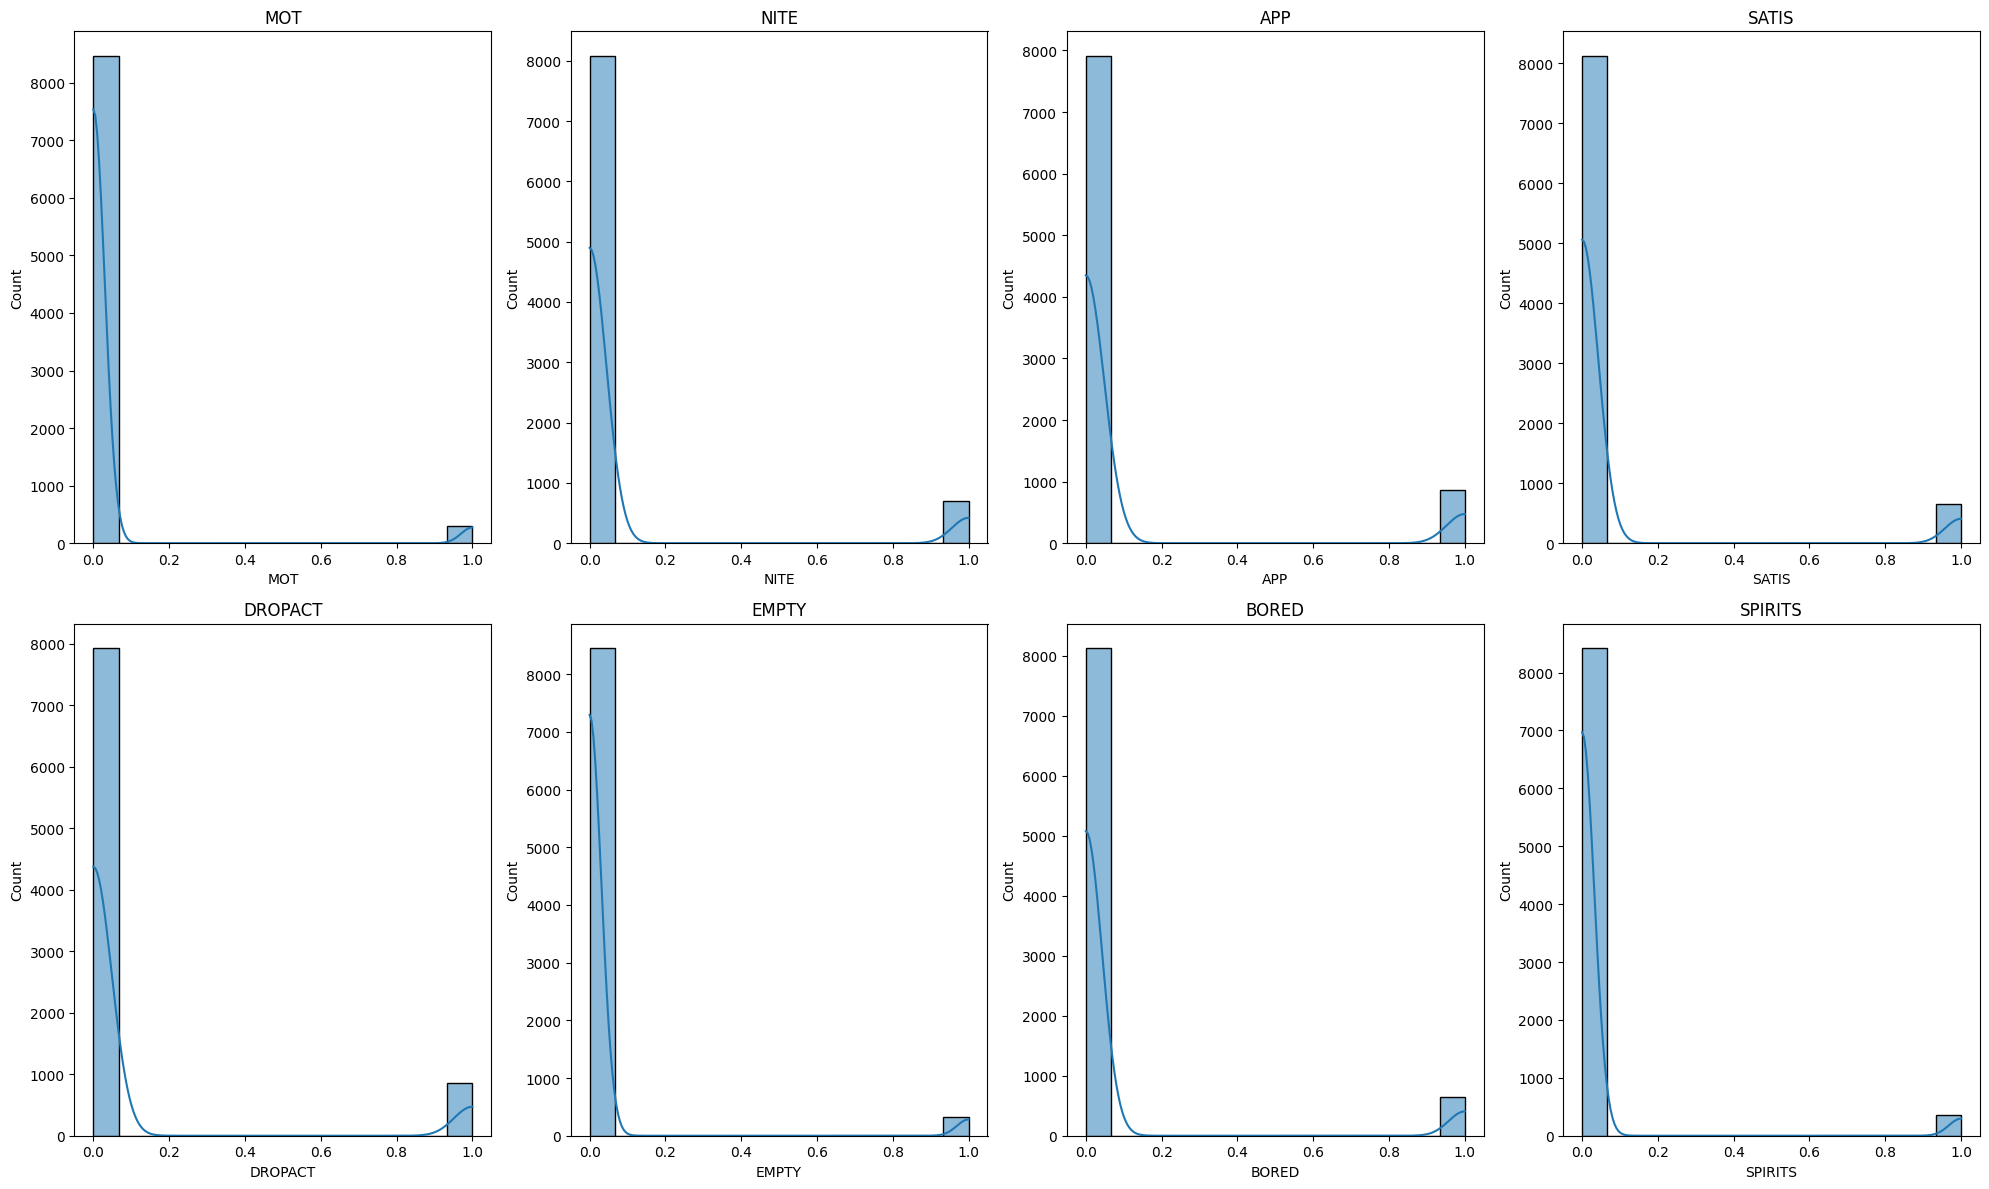

In [69]:
cols = knn_Imputer(cols.columns,3)
visualize_counts(2,4,cols=cols)

In [70]:
for col in cols:
    print(df[col].value_counts())

MOT
0    8470
1     307
Name: count, dtype: int64
NITE
0    8083
1     694
Name: count, dtype: int64
APP
0    7915
1     862
Name: count, dtype: int64
SATIS
0    8123
1     654
Name: count, dtype: int64
DROPACT
0    7924
1     853
Name: count, dtype: int64
EMPTY
0    8450
1     327
Name: count, dtype: int64
BORED
0    8128
1     649
Name: count, dtype: int64
SPIRITS
0    8420
1     357
Name: count, dtype: int64


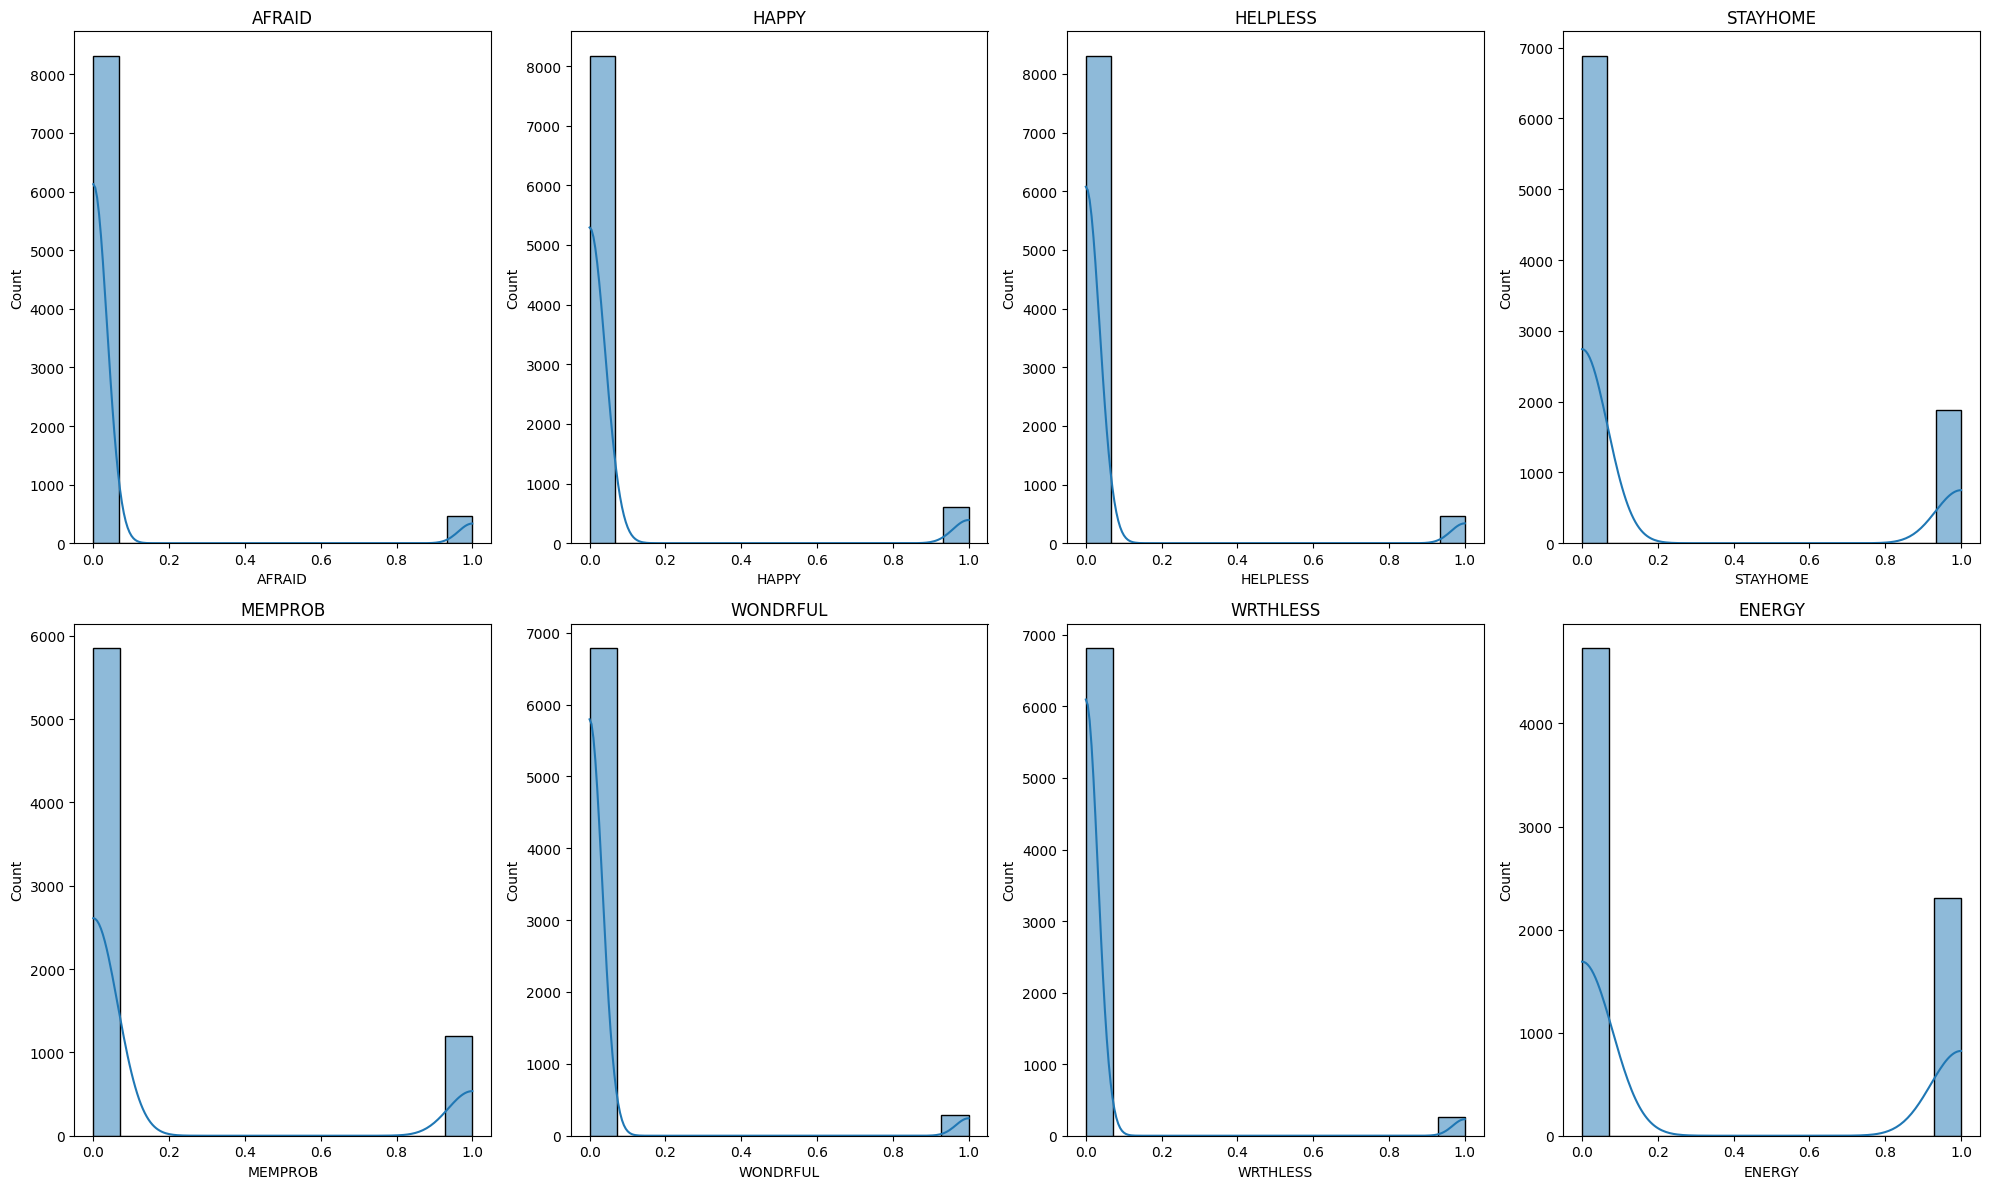

In [71]:
cols1 = df.iloc[:,56:64]
for col in cols1:
    df[col] = df[col].replace(9, np.nan) 


visualize_counts(2,4,cols=cols1)

In [72]:
cols1 = knn_Imputer(cols1.columns,3)
for col in cols1:
    print(df[col].value_counts())


AFRAID
0    8321
1     456
Name: count, dtype: int64
HAPPY
0    8177
1     600
Name: count, dtype: int64
HELPLESS
0    8314
1     463
Name: count, dtype: int64
STAYHOME
0    6895
1    1882
Name: count, dtype: int64
MEMPROB
0    7577
1    1200
Name: count, dtype: int64
WONDRFUL
0    8493
1     284
Name: count, dtype: int64
WRTHLESS
0    8519
1     258
Name: count, dtype: int64
ENERGY
0    6473
1    2304
Name: count, dtype: int64


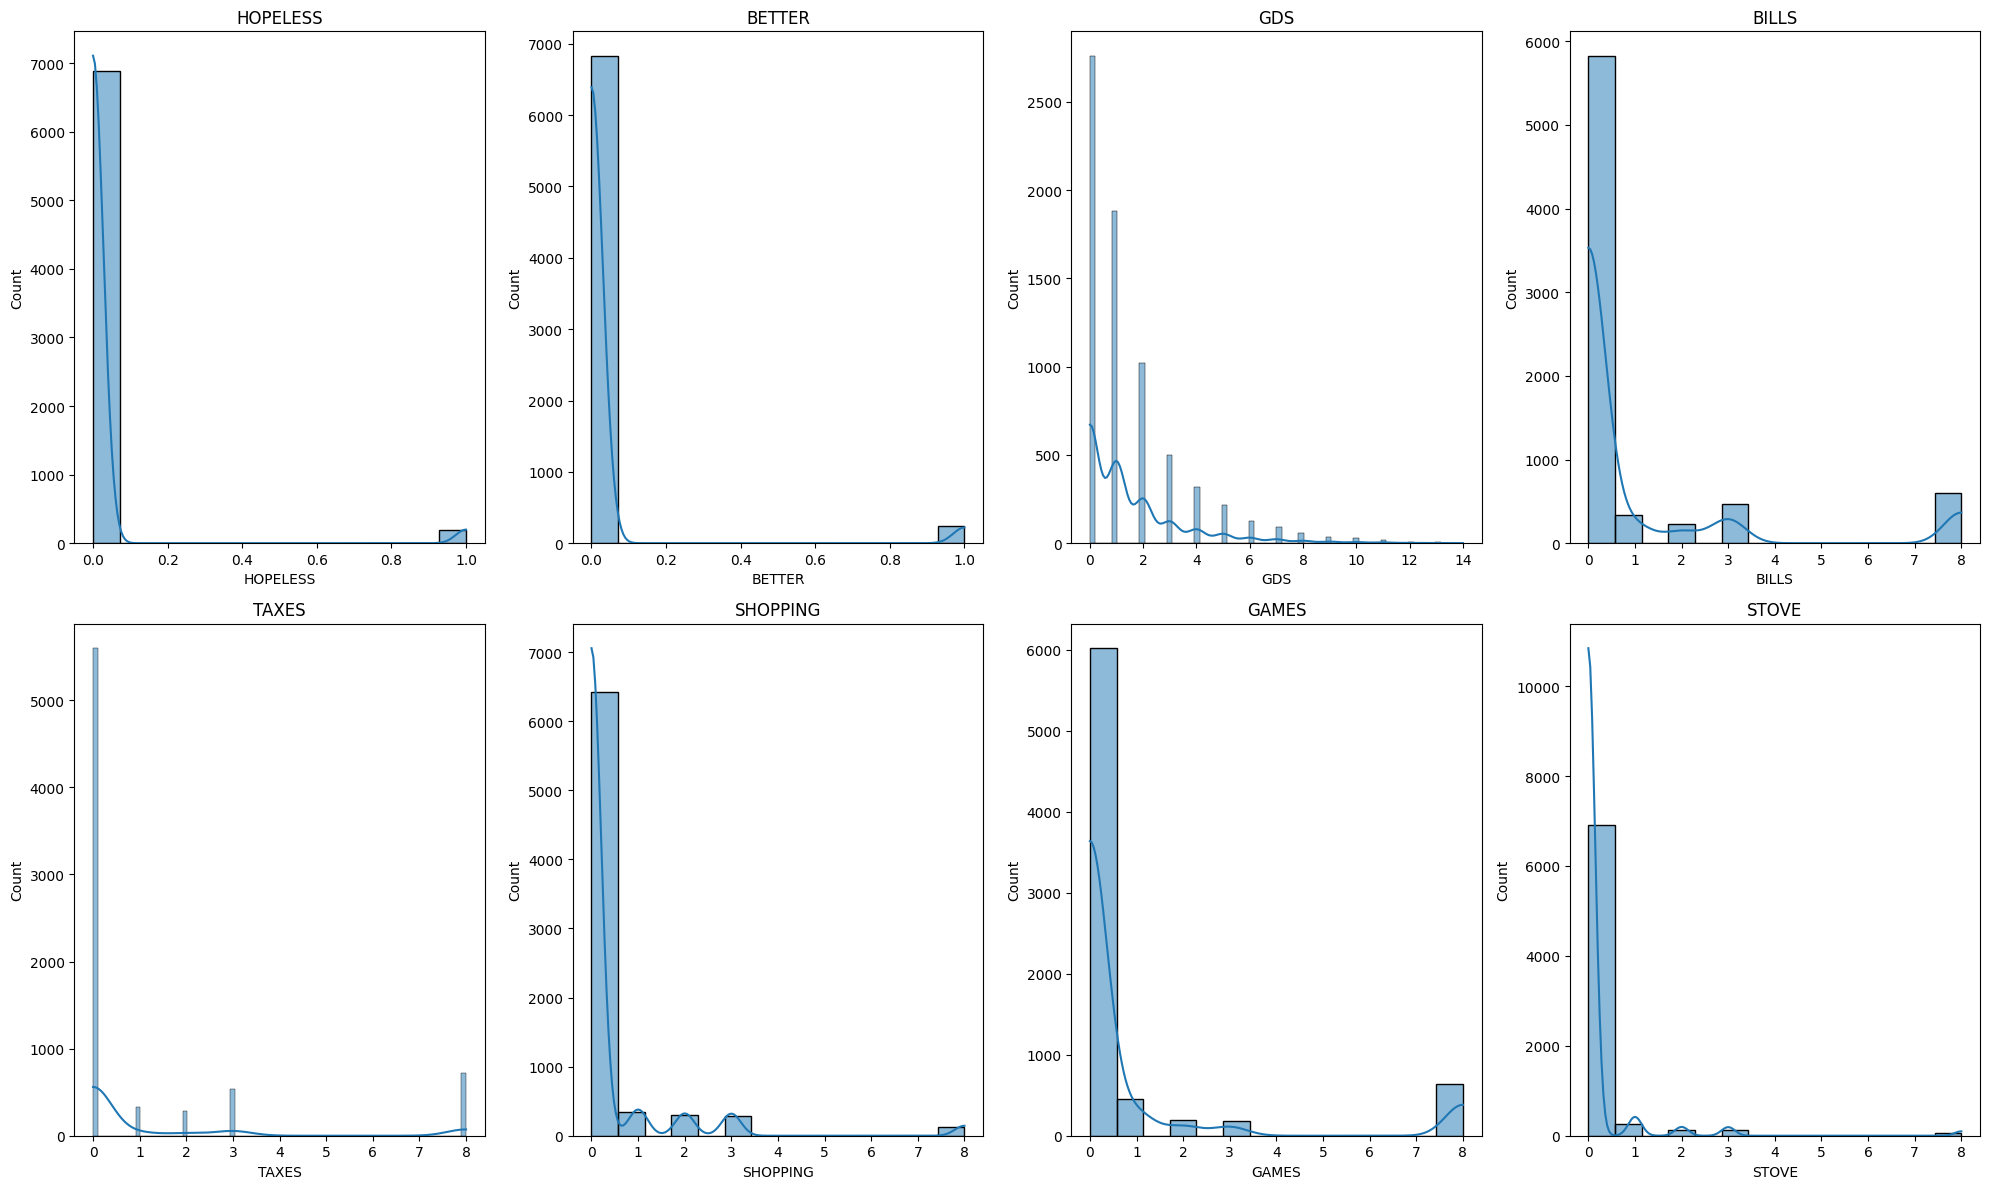

In [73]:
cols2 = df.iloc[:,64:72]
for col in cols2:
    if col == "GDS": 
        continue
    df[col] = df[col].replace(9, np.nan) 
visualize_counts(2,4,cols=cols2)

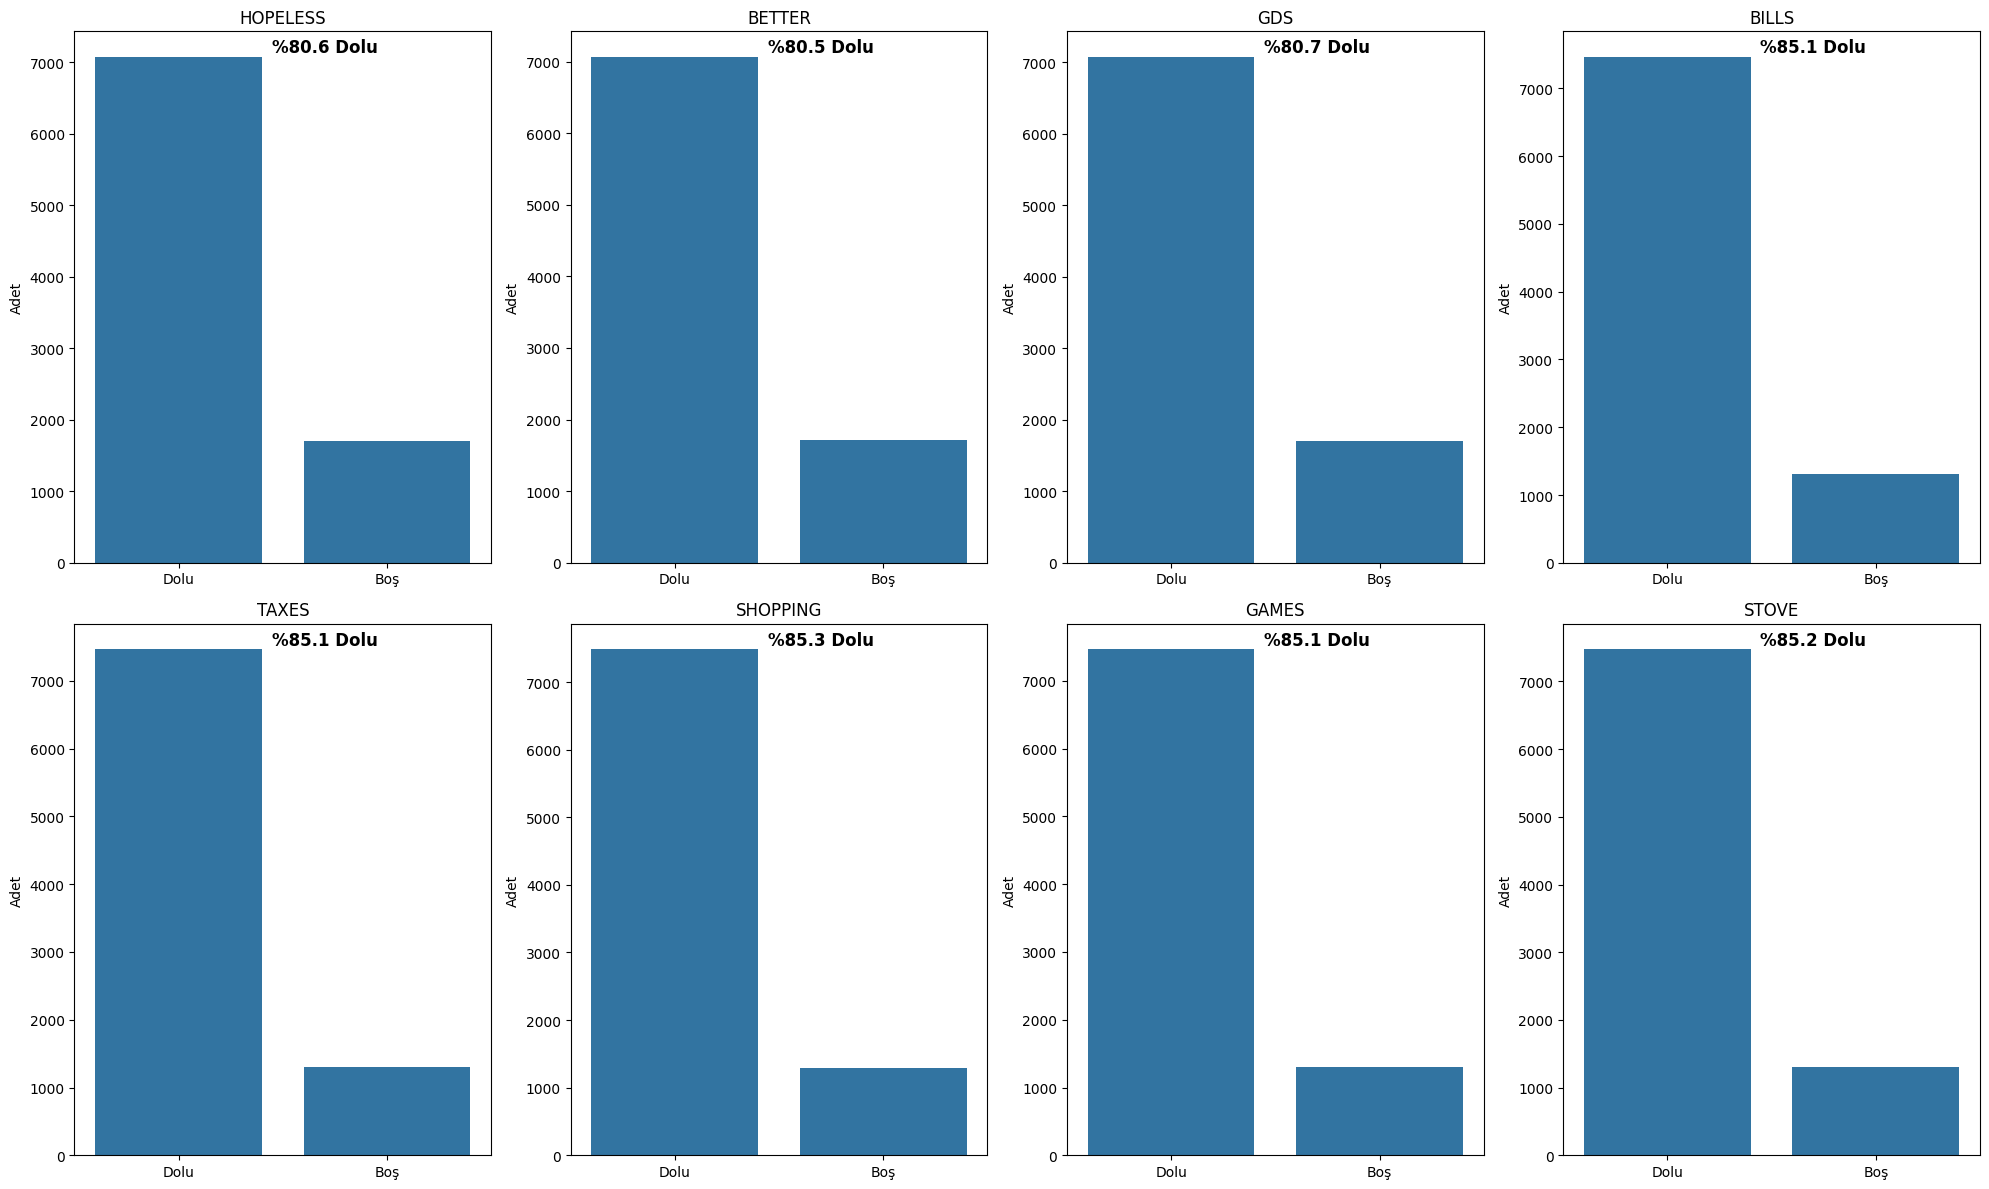

In [74]:
visualize_nullValue(2,4,cols=cols2)

In [75]:
for col in cols2:
    print(df[col].value_counts())

HOPELESS
0.0    6883
1.0     192
Name: count, dtype: int64
BETTER
0.0    6833
1.0     235
Name: count, dtype: int64
GDS
0.0     2761
1.0     1883
2.0     1022
3.0      499
4.0      320
5.0      217
6.0      127
7.0       92
8.0       57
9.0       37
10.0      27
11.0      20
12.0       9
13.0       7
14.0       2
Name: count, dtype: int64
BILLS
0.0    5827
8.0     605
3.0     469
1.0     339
2.0     229
Name: count, dtype: int64
TAXES
0.0    5597
8.0     724
3.0     537
1.0     331
2.0     279
Name: count, dtype: int64
SHOPPING
0.0    6426
1.0     345
2.0     294
3.0     291
8.0     131
Name: count, dtype: int64
GAMES
0.0    6016
8.0     633
1.0     447
2.0     192
3.0     180
Name: count, dtype: int64
STOVE
0.0    6902
1.0     267
2.0     125
3.0     122
8.0      62
Name: count, dtype: int64


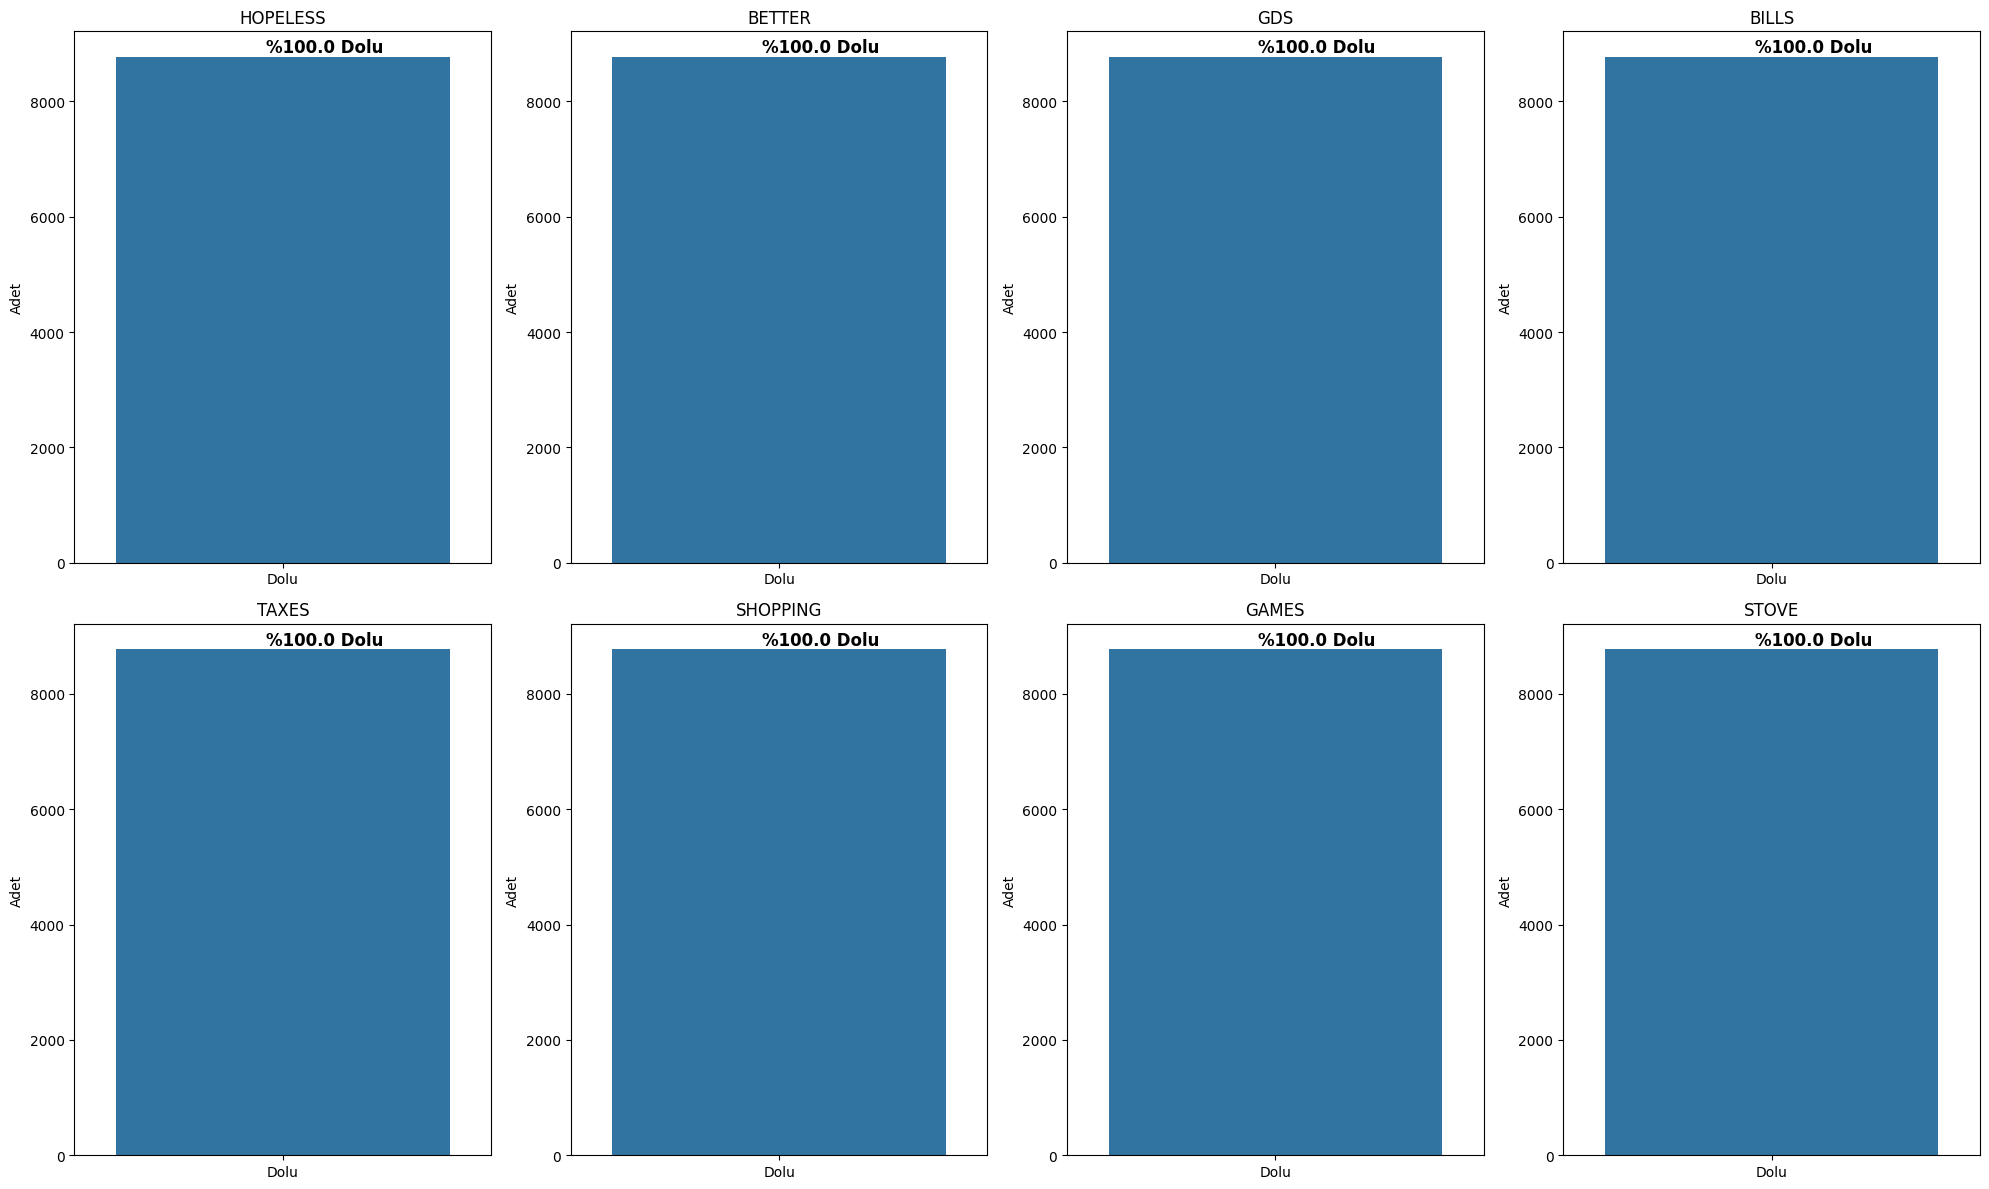

In [76]:
knn_arr = ["HOPELESS","BETTER","BILLS","SHOPPING","GAMES","STOVE"]
median_arr = ["GDS","TAXES"]
cols_knn = knn_Imputer(knn_arr,3)
cols_median = simple_Imputer(median_arr,"median")

visualize_nullValue(2,4,cols=cols2)



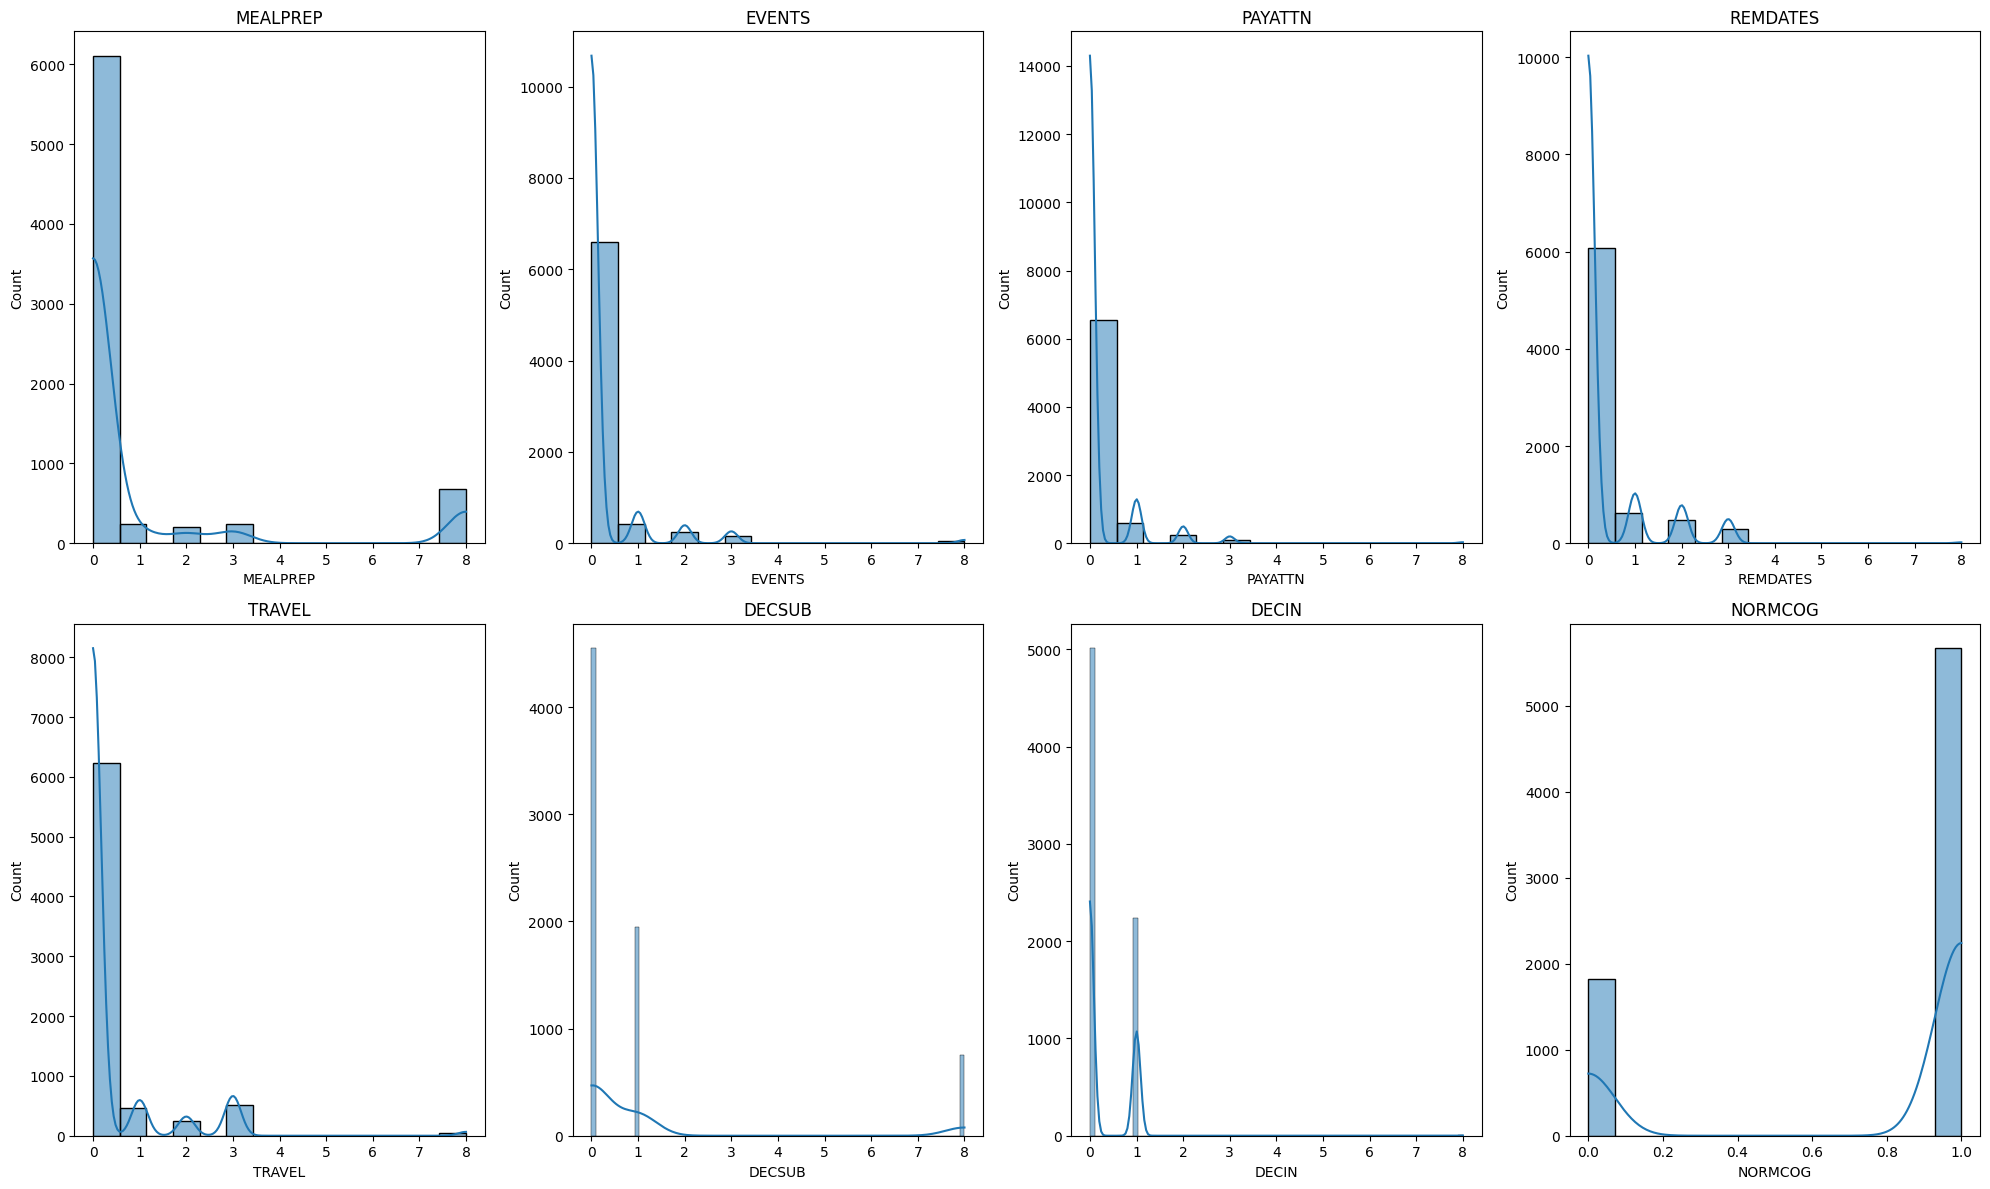

In [77]:
cols3 = df.iloc[:,72:80]
for col in cols3:
    df[col] = df[col].replace(9, np.nan)

visualize_counts(2,4,cols=cols3)  

In [78]:
knn_arr = ['EVENTS', 'PAYATTN', 'REMDATES', 'TRAVEL', 'NORMCOG']
mod_arr = ['MEALPREP','DECSUB','DECIN']
cols_knn = knn_Imputer(knn_arr,3)
cols_median = simple_Imputer(mod_arr,"most_frequent")



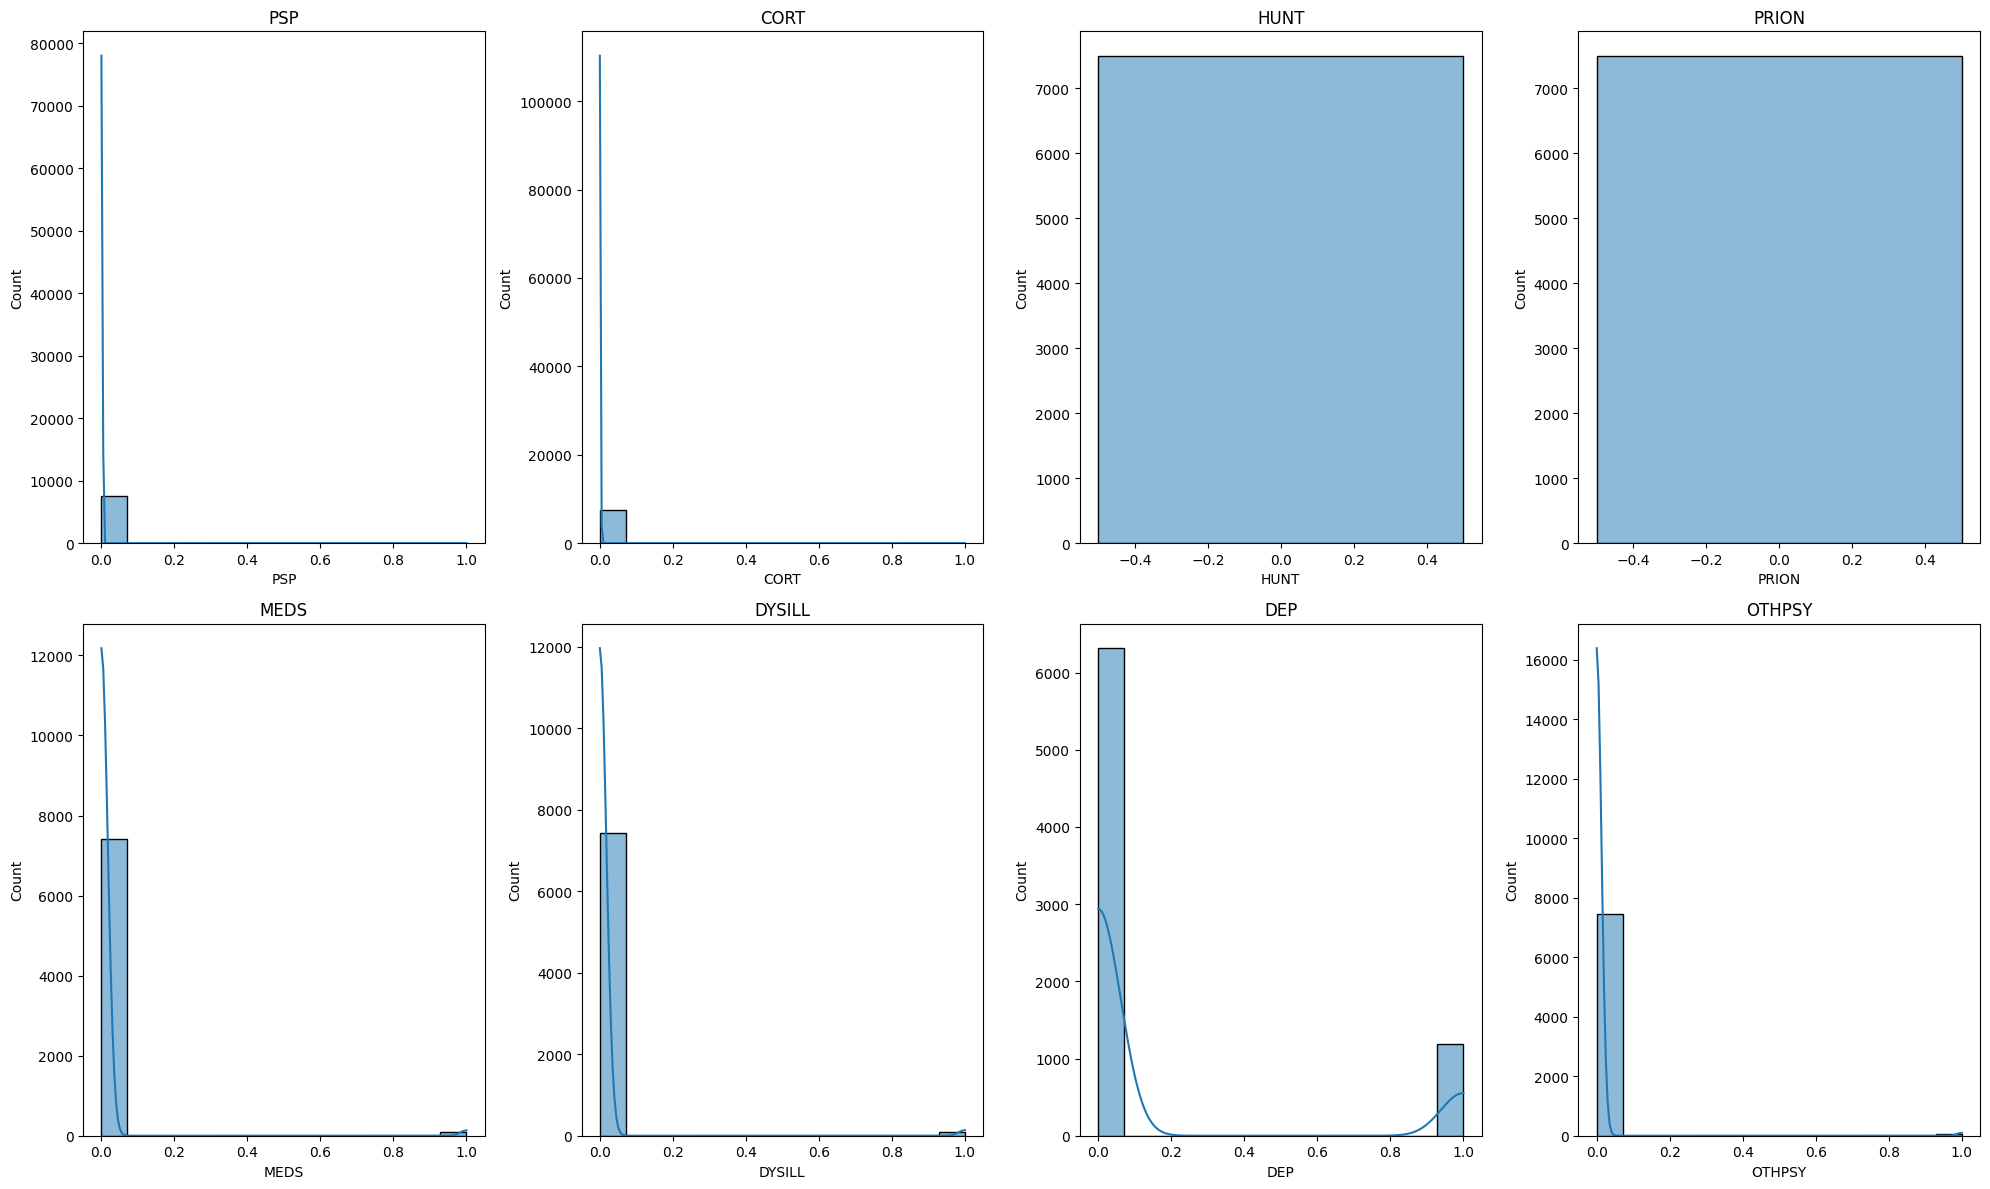

In [79]:
cols4 = df.iloc[:,80:88]
for col in cols3:
    df[col] = df[col].replace(9, np.nan)
visualize_counts(2,4,cols=cols4)

In [80]:
cols4.columns

Index(['PSP', 'CORT', 'HUNT', 'PRION', 'MEDS', 'DYSILL', 'DEP', 'OTHPSY'], dtype='object')

In [81]:
knn_arr = ["DEP"]
mod_arr = ['PSP', 'CORT', 'HUNT', 'PRION', 'MEDS', 'DYSILL','OTHPSY']
cols_knn = knn_Imputer(knn_arr,3)
cols_median = simple_Imputer(mod_arr,"most_frequent")

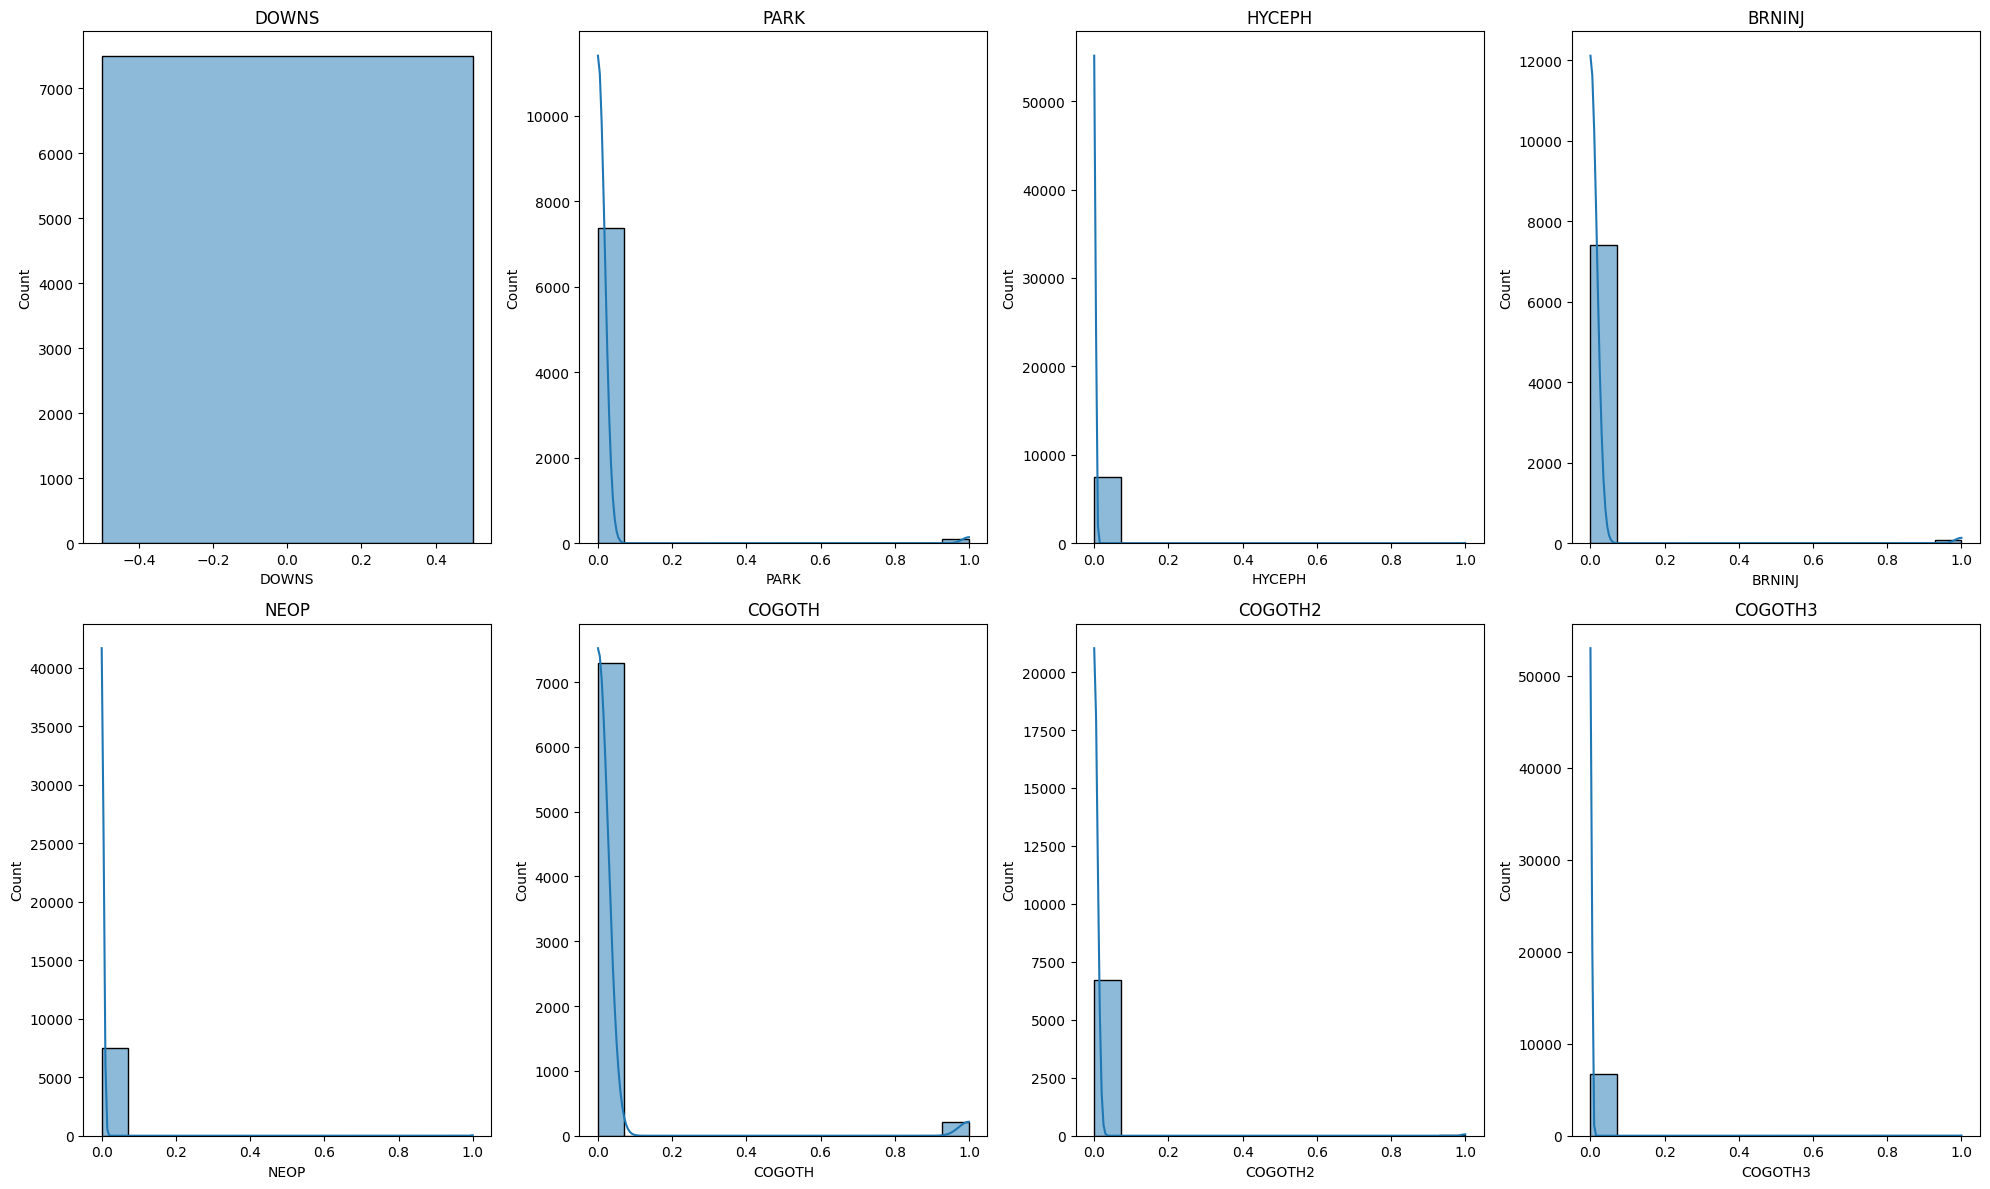

In [82]:
cols5 = df.iloc[:,88:96]
for col in cols3:
    df[col] = df[col].replace(9, np.nan)
visualize_counts(2,4,cols=cols5)

In [83]:
cols5 = simple_Imputer(cols5.columns,"most_frequent")

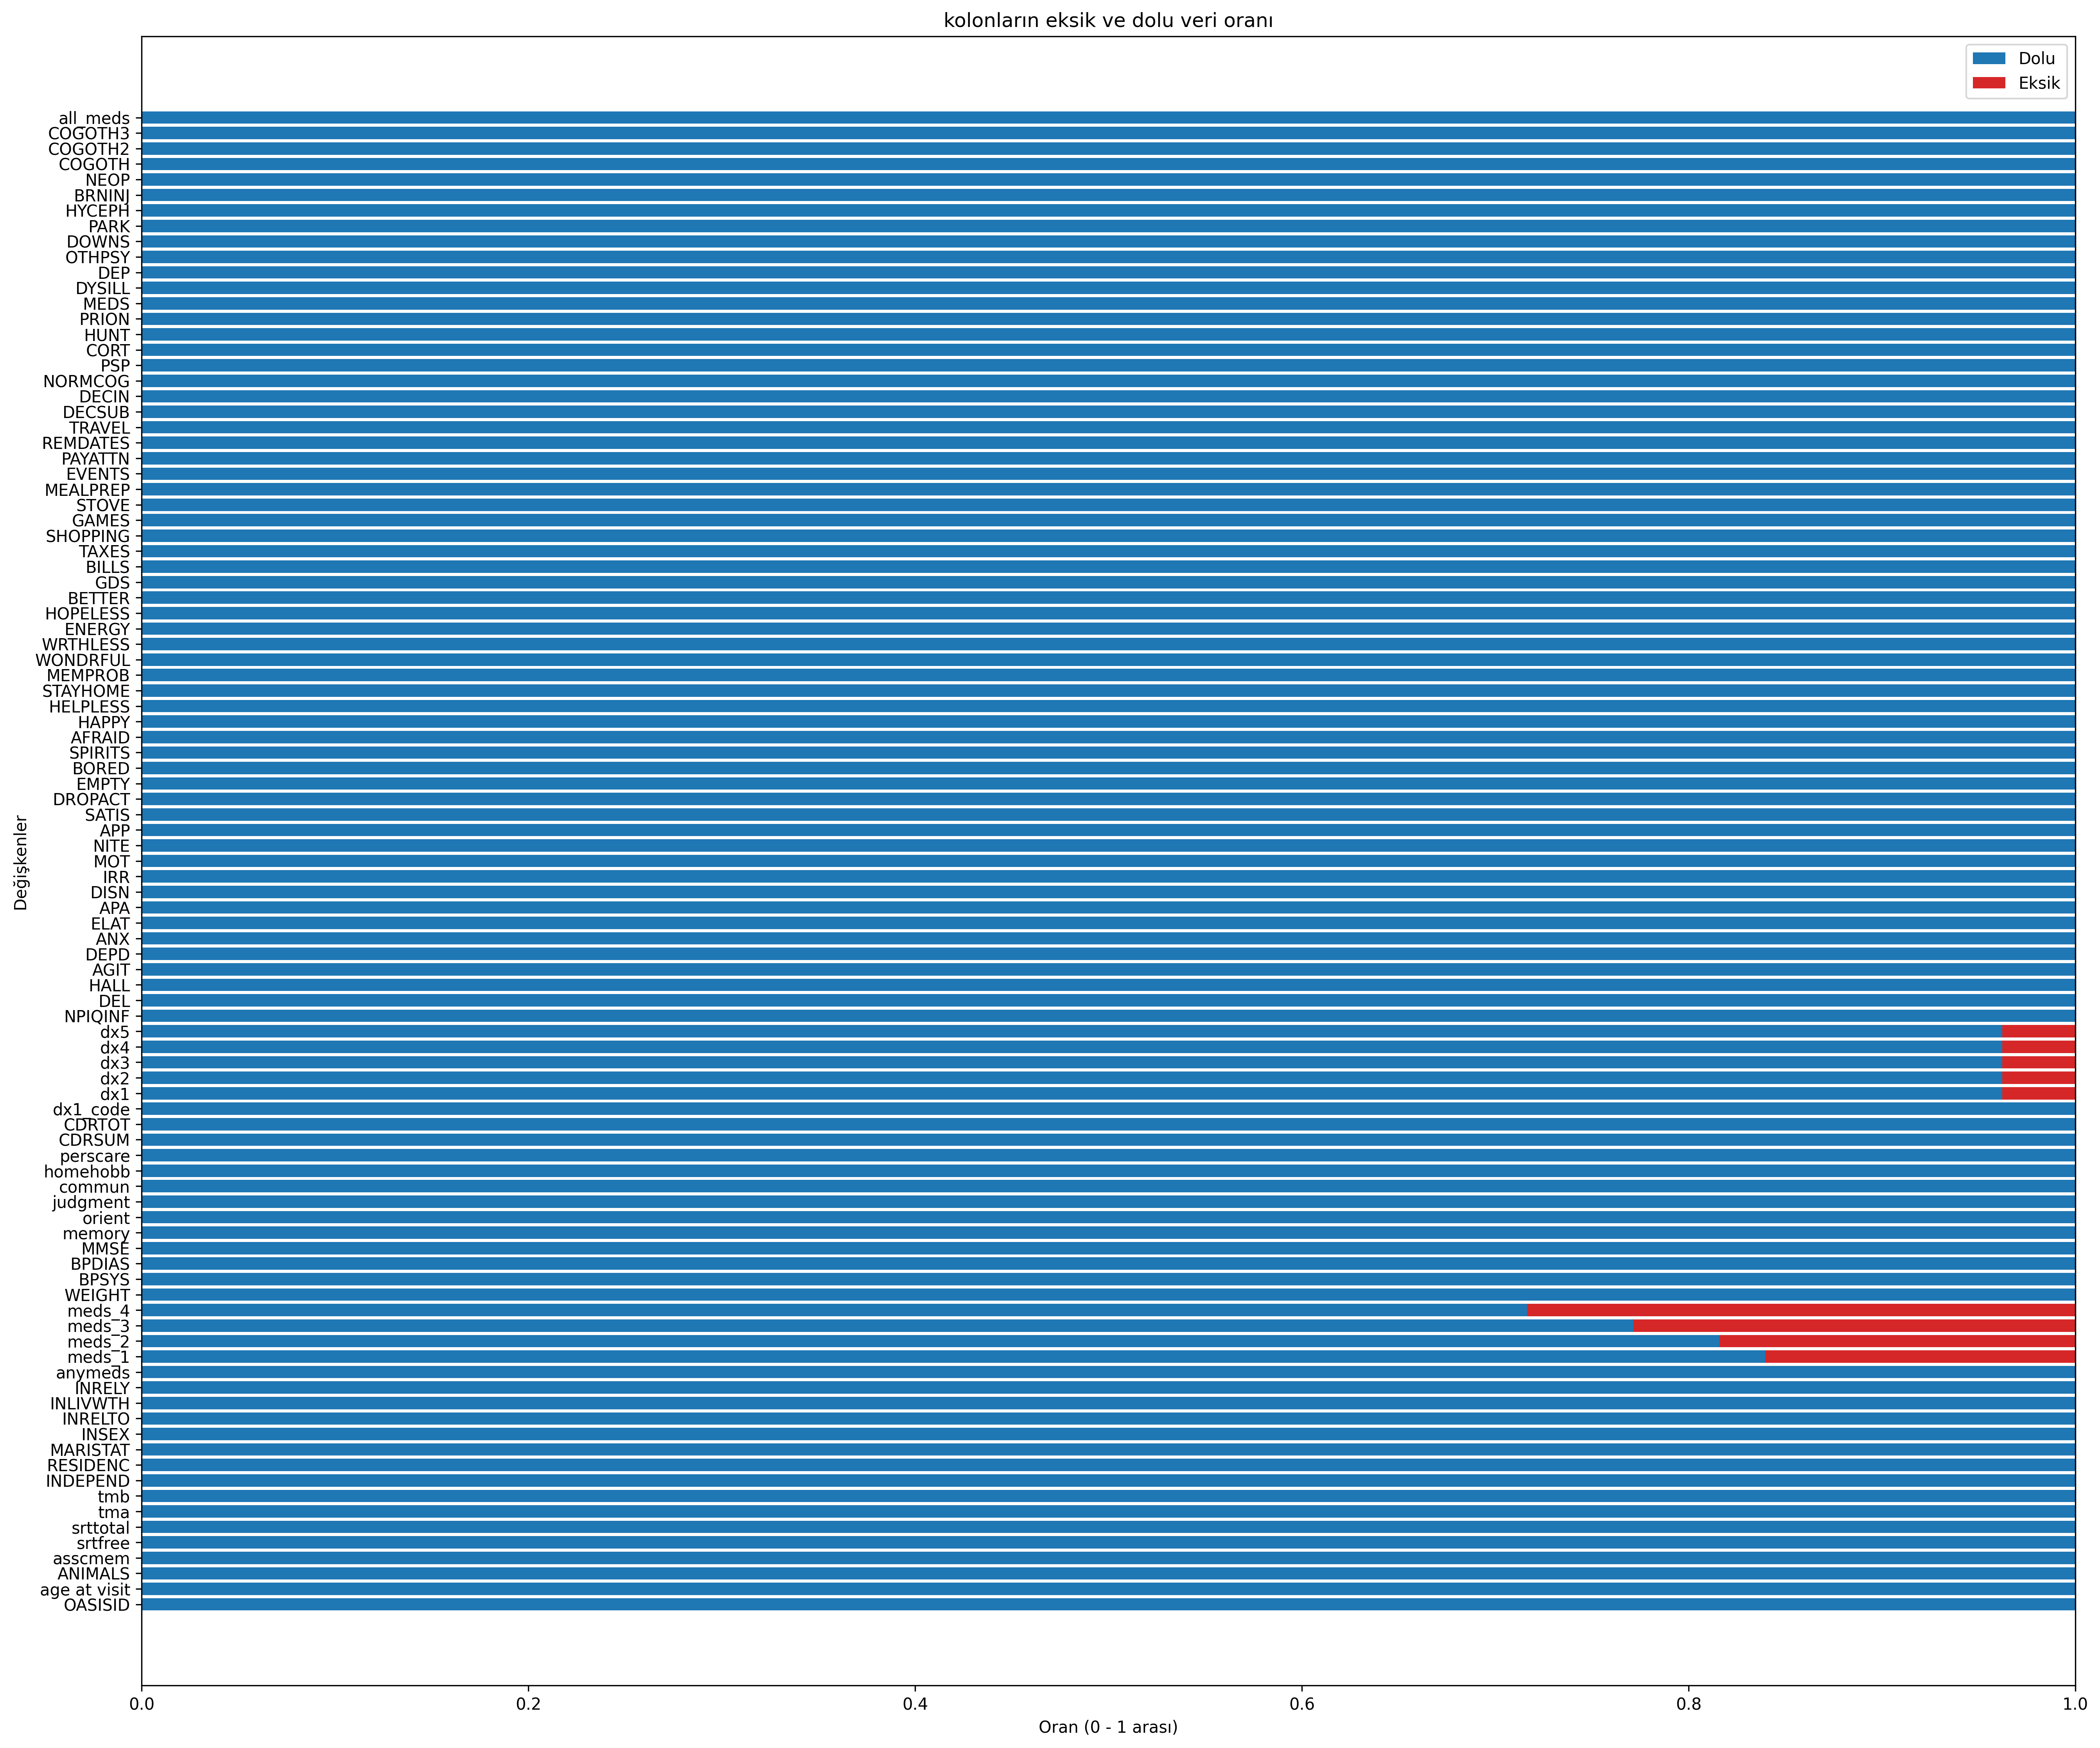

In [84]:
visualize_all()

In [85]:
df.to_csv("filled1_data.csv", index=False)